# N3 · Experimentos de observación única

Un **experimento** es una asimilación evaluada en una celda: un (dataset, hora, miembro verdad, celda observada) y un esquema. Para una variable $\phi$, $e = \overline{\phi} - \phi_\mathrm{true}$ en el prior ($f$) y en el posterior ($a$); para $Z$ la verdad es $h(\mathbf{x}_\mathrm{true})$ sin ruido, y para $q_g+q_r+q_s$ el error es la suma de los errores con signo de las tres especies.

Para una población $P$ de experimentos:

- $\mathrm{RMSE}(P) = \sqrt{\sum e^2 / |P|}$ y $\mathrm{CRPS}(P) = \sum \mathrm{CRPS}_k / |P|$, prior y posterior;
- $\mathrm{SS}_\mathrm{RMSE} = 1 - \mathrm{RMSE}_a/\mathrm{RMSE}_f$, $\mathrm{SS}_\mathrm{CRPS} = 1 - \mathrm{CRPS}_a/\mathrm{CRPS}_f$;
- fracción que mejora $F$: entre los experimentos que cambian ($\big||e_f| - |e_a|\big|$ mayor que la tolerancia de la variable), la parte con $|e_a| < |e_f|$; probabilidad de degradación $= 1 - F$.

**Valor central:** el estadístico sobre la población agrupada (todas las verdades, horas y celdas). **Banda:** ±1 desviación estándar del mismo estadístico calculado por miembro verdad, con sus cuatro horas juntas (60 valores).

Sección 0: el postprocesado, de los archivos crudos a las sumas. Las celdas de análisis calculan los números; las de figura solo dibujan.

In [ ]:
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import nbcommon as nb

REBUILD = False           # True: rehace los intermedios desde los archivos crudos (~20 min)
SHOW = "es"               # el idioma que se muestra en línea; se guardan los dos

# Umbrales de los gráficos por bin: un bin se dibuja si su población agrupada tiene al
# menos N_MIN_BIN experimentos, y un miembro verdad entra en la banda de un bin si
# tiene al menos N_MIN_TRUTH experimentos ahí.
N_MIN_BIN = 200
N_MIN_TRUTH = 20

nb.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

In [2]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB.
LABELS = {
    "es": {
        "Z": "$Z$", "w": "$w$", "qtot": "$q_g+q_r+q_s$",
        "ss_rmse_truth": r"$\mathrm{SS}_{\mathrm{RMSE}}$ por miembro verdad",
        "norm_innov": "innovación normalizada",
        "share": "fracción de los experimentos",
        "retained": "retenidas",
        "all": "todas",
        "alpha_s": r"$\alpha_s$",
    },
    "en": {
        "Z": "$Z$", "w": "$w$", "qtot": "$q_g+q_r+q_s$",
        "ss_rmse_truth": r"$\mathrm{SS}_{\mathrm{RMSE}}$ per truth member",
        "norm_innov": "normalized innovation",
        "share": "share of experiments",
        "retained": "retained",
        "all": "all",
        "alpha_s": r"$\alpha_s$",
    },
}
for _l in nb.LANGS:
    LABELS[_l]["n_active"] = f"{nb.VOCAB[_l]['n_echo']}, {nb.VOCAB[_l]['n_echo_sym']}"
assert set(LABELS["es"]) == set(LABELS["en"])

DS_COLORS = {"A": nb.C_NT1, "B": nb.C_NT2, "C": nb.C_NONE}
GR_COLORS = {"obs": "k", "w": "#8B0000", "qtot": "#1f77b4"}
DSL = nb.DS_LABEL

## 0 · Postprocesado

Lee los 720 archivos del barrido (A, B, C × 4 horas × 60 miembros verdad) y los 60 de la corrida con $\alpha_s = 0{,}25$, y escribe sumas en `data/derived/N3/N3_sums_*.csv`.

| archivo | una fila |
|---|---|
| `N3_sums_base.csv` | (dataset, hora, miembro verdad, esquema, variable) |
| `N3_sums_rule.csv` | lo mismo por regla de rechazo (`none`, `d[0,10]`, `d[2,8]`) |
| `N3_sums_bins.csv` | (dataset, miembro verdad, esquema, variable, predictor, bin), con las cuatro horas juntas; variables $Z$, $w$ y $q_g+q_r+q_s$ |
| `N3_sums_weights.csv` | (α_s, miembro verdad, esquema, variable): A a las 19 UTC con α_s = 1 y 0,25 |
| `N3_sums_weights_split.csv` | (α_s, miembro verdad, $N_t$ ∈ {3, 5}, mitad): $Z$ con $|e_f|$ por debajo (≤) y por encima de su mediana agrupada |
| `N3_sums_obs.csv` | (dataset, hora, miembro verdad): celdas, celdas con eco en la verdad, celdas donde AOEI infla R |
| `N3_sums_runs.csv`, `N3_sums_weights_runs.csv` | la identidad y la configuración de cada corrida |

Columnas de suma: `n` (experimentos con error finito), `n_nan`, `se2_f`, `se2_a` ($\sum e^2$), `sae_f`, `sae_a` ($\sum|e|$), `scrps_f`, `scrps_a` ($\sum \mathrm{CRPS}$; vacías para $q_g+q_r+q_s$, que no tiene CRPS en los archivos), `ssp_f`, `ssp_a`, `ssp2_f`, `ssp2_a` ($\sum\sigma$, $\sum\sigma^2$ de la dispersión en la celda; vacías para $q_g+q_r+q_s$), `n_change`, `n_imp`. Para $Z$, $|e|$ es la columna `rmse_*_point_obs` del archivo, que es |media − verdad|; para el estado, media − verdad en float64.

En serie: con `spawn` (macOS) no hay workers.

In [3]:
OUT = nb.DERIVED / "N3"
PREFIX = "N3_sums"

DATASETS = ("A", "B", "C")
HOURS = ("18", "19", "20", "21")
TMS = tuple(range(60))
LOC = 0.1
NTEMP_REQ = tuple(range(1, 11))
STRIDE_REQ = 10

STATE = tuple(nb.VARS)                       # qg, qr, qs, T, P, u, v, w
HYDRO = ("qg", "qr", "qs")
VARS = ("obs",) + STATE + ("qtot",)          # obs = Z
# Banda de empate de cada variable, en sus unidades; qtot lleva la de los hidrometeoros.
TOLS = {"obs": nb.TOL["obs"], **{v: nb.TOL[v] for v in STATE}, "qtot": 1e-7}
NO_CRPS = ("qtot",)                          # el CRPS de la suma no está en los archivos

# La regla rechaza la observación si lo ≤ d ≤ hi.
RULES = {"none": None, "d[0,10]": (0.0, 10.0), "d[2,8]": (2.0, 8.0)}
EDGES = {
    "dep_b":            np.arange(-30.0, 30.001, 2.0),
    "norm_innov":       np.arange(0.0, 6.001, 0.25),
    "n_active_f_point": np.arange(-0.5, 59.51, 1.0),
}
BIN_VARS = ("obs", "w", "qtot")
NORM_INNOV_AOEI = 1.0                        # AOEI infla R si d² > σ_f² + R

IDENT_TOL = 1e-3                             # dBZ, identidad por H(x) de la verdad
RMSE_ID_RTOL, RMSE_ID_ATOL_REL = 1e-5, 1e-6  # |media − verdad| contra rmse_*_point_v

W_DS, W_HOUR = "A", "19"
W_RUNS = {1.0: "WS_A_sweep_1900_LOC0.1_ALLMEM", 0.25: "WS_A_sweep_1900_LOC0.1_ALLMEM_AS0.25"}
W_CELLS = ((3, 1.0), (3, 0.25), (5, 1.0), (5, 0.25))
W_CONTROL = (("TEnKF", 1), ("AOEI", 1))      # no usan α_s: idénticos en las dos corridas

SUMS = ["n", "se2_f", "se2_a", "sae_f", "sae_a", "scrps_f", "scrps_a",
        "ssp_f", "ssp_a", "ssp2_f", "ssp2_a", "n_change", "n_imp"]
FILES = {k: OUT / f"{PREFIX}_{k}.csv" for k in ("runs", "base", "rule", "bins", "obs")}
# El experimento de pesos tiene su propio disparador: rehacerlo no rehace el barrido.
W_FILES = {k: OUT / f"{PREFIX}_{k}.csv" for k in ("weights", "weights_runs", "weights_split")}


def lab(method, ntemp):
    return "AOEI" if method == "AOEI" else f"TEnKF-T{int(ntemp)}"


def scheme_order(c):
    return (0 if c[0] == "AOEI" else 1, int(c[1]))


def run_of(ds, hour):
    return f"WS_{ds}_sweep_{hour}00_LOC{LOC}_ALLMEM"

In [4]:
# ── Identidad de las corridas ────────────────────────────────────────────────

def identity_err(f, hh, ds, dbz_min):
    """Máx |yo_clean − H(x) de la verdad recalculada desde el subset del dataset ds|.

    yo_clean es H(x) del miembro verdad sin ruido: en el dataset correcto difiere solo
    por redondeo (~2e-6 dBZ), en otro por decenas de dBZ. Para archivos sin dataset_id.
    """
    tm = int(f.rsplit("_tm", 1)[1][:2])
    with np.load(f) as z:
        one = (z["method"] == z["method"][0]) & (z["ntemp"] == z["ntemp"][0])
        i, j, k = (z[c][one].astype(np.intp) for c in ("i", "j", "k"))
        yc = z["yo_clean"][one].astype(float)
    truth = nb.load_ensemble(nb.subset_path(hh, ds), members=[tm])[i, j, k, 0, :]
    return float(np.max(np.abs(nb.hx(truth, min_dbz=dbz_min) - yc)))


def preflight():
    """Qué corridas califican, y que cada una sea del dataset que su tag dice.

    La cadena es tag -> config -> subset usado -> dataset_id; si el archivo no trae
    dataset_id (A), la identidad se comprueba con H(x) de la verdad.
    """
    rows = []
    for ds in DATASETS:
        for hh in HOURS:
            tag = run_of(ds, hh)
            cfg = nb.run_config(tag)
            did_used = nb.dataset_of(cfg["paths"]["prepared"])
            did_want = nb.dataset_of(nb.subset_path(hh, ds))
            if did_used is not None and did_want is not None:
                assert did_used == did_want, f"{tag} se corrió sobre el dataset {did_used}"
            f = nb.sweep_files(tag, [0])[0]
            did = nb.assert_dataset(f, ds, what=tag)
            if nb.dataset_of(f) is None:
                id_source, id_err = "H(x) del subset", identity_err(f, hh, ds, nb.dbz_min_of(tag))
                assert id_err < IDENT_TOL, f"{tag}: no es el dataset {ds} ({id_err:.3g} dBZ)"
            else:
                id_source, id_err = "dataset_id", np.nan
            sw = cfg["sweep"]
            rows.append(dict(dataset=ds, hour=hh, tag=tag, dataset_id=did, id_source=id_source,
                             id_err_dbz=id_err, stride=int(sw["stride"]),
                             ntemp=str([int(n) for n in sw["ntemp"]]),
                             methods=str(list(sw["methods"])), n_files=len(nb.sweep_files(tag)),
                             Ne=int(f.split("_Ne")[1][:3]), R=nb.obs_error_var(tag),
                             dbz_min=nb.dbz_min_of(tag),
                             qualifies=(tuple(int(n) for n in sw["ntemp"]) == NTEMP_REQ
                                        and int(sw["stride"]) == STRIDE_REQ)))
    return pd.DataFrame(rows)


def weights_preflight():
    """Que las dos corridas de pesos difieran solo en α_s, leído de las configs."""
    rows = []
    for a, tag in W_RUNS.items():
        cfg, files = nb.run_config(tag), nb.sweep_files(tag)
        ids = {nb.dataset_of(f) for f in files}
        assert len(ids) == 1, f"{tag}: archivos con dataset_id distintos {ids}"
        did = ids.pop()
        if did is None:
            id_source, id_err = "H(x) del subset", identity_err(files[0], W_HOUR, W_DS, nb.dbz_min_of(tag))
            assert id_err < IDENT_TOL, f"{tag}: no es el dataset {W_DS} ({id_err:.3g} dBZ)"
        else:
            assert did == W_DS, f"{tag}: dataset_id {did}, se esperaba {W_DS}"
            id_source, id_err = "dataset_id", np.nan
        sw = cfg["sweep"]
        rows.append(dict(alpha_s=a, tag=tag, alpha_s_cfg=float(sw["alpha_s"]), dataset_id=did,
                         id_source=id_source, id_err_dbz=id_err, n_files=len(files),
                         n_members=int(cfg["state"]["n_members"]), stride=int(sw["stride"]),
                         loc_x=float(sw["loc_x"]), R=nb.obs_error_var(tag),
                         dbz_min=nb.dbz_min_of(tag), ntemp=str([int(n) for n in sw["ntemp"]]),
                         methods=str(list(sw["methods"]))))
    W = pd.DataFrame(rows)
    assert (W.alpha_s_cfg == W.alpha_s).all(), "el α_s de la config no es el del tag"
    core = []
    for tag in W_RUNS.values():
        c = copy.deepcopy(nb.run_config(tag))
        c.pop("experiment_tag"); c["paths"].pop("outdir"); c["sweep"].pop("alpha_s")
        core.append(c)
    assert core[0] == core[1], "las configs difieren en algo más que α_s"
    assert (W.n_files == W.n_members).all(), "falta algún miembro verdad"
    return W

In [5]:
# ── Un archivo: errores por esquema y variable ───────────────────────────────

KEYS = (["i", "j", "k", "method", "ntemp", "yo", "yo_clean", "dep_b", "n_active_f_point",
         "rmse_f_point_obs", "rmse_a_point_obs", "crps_f_point_obs", "crps_a_point_obs",
         "spread_f_point_obs", "spread_a_point_obs"]
        + [f"{p}_point_{v}" for v in STATE
           for p in ("mean_f", "mean_a", "truth", "rmse_f", "rmse_a",
                     "crps_f", "crps_a", "spread_f", "spread_a")])


def read_file(f, R):
    """Un archivo del barrido -> filas por esquema, predictores y errores.

    Los esquemas tienen que compartir celdas y predictores: se comprueba, no se supone.
    Los predictores se calculan en float32, como antes, para que caigan en los mismos
    bins.
    """
    with np.load(f) as z:
        A = {k: z[k] for k in KEYS}
    meth, nt = A["method"].astype(str), A["ntemp"].astype(int)
    dims = tuple(int(A[c].max()) + 1 for c in ("i", "j", "k"))
    key = np.ravel_multi_index((A["i"], A["j"], A["k"]), dims)
    schemes = sorted(set(zip(meth, nt)), key=scheme_order)
    rows, ref = {}, None
    for sc in schemes:
        r = np.flatnonzero((meth == sc[0]) & (nt == sc[1]))
        r = r[np.argsort(key[r], kind="stable")]
        if ref is None:
            ref = r
            assert np.unique(key[r]).size == r.size, f"{f}: celdas repetidas en {sc}"
        else:
            assert np.array_equal(key[r], key[ref]), f"{f}: {sc} tiene otras celdas"
            for p in ("dep_b", "n_active_f_point", "spread_f_point_obs", "yo", "yo_clean"):
                assert np.array_equal(A[p][r], A[p][ref], equal_nan=True), f"{f}: {p} depende del esquema"
        rows[sc] = r
    dep32 = A["dep_b"][ref]
    pred = {"dep_b": dep32.astype(float),
            "norm_innov": (np.abs(dep32) / np.sqrt(A["spread_f_point_obs"][ref] ** 2 + R)).astype(float),
            "n_active_f_point": A["n_active_f_point"][ref].astype(float)}
    obs = dict(yo_clean=A["yo_clean"][ref].astype(float))

    err = {}
    for sc, r in rows.items():
        E = {"obs": dict(ef=A["rmse_f_point_obs"][r].astype(float), ea=A["rmse_a_point_obs"][r].astype(float),
                         cf=A["crps_f_point_obs"][r].astype(float), ca=A["crps_a_point_obs"][r].astype(float),
                         sf=A["spread_f_point_obs"][r].astype(float), sa=A["spread_a_point_obs"][r].astype(float))}
        q = {"f": np.zeros(r.size), "a": np.zeros(r.size)}
        for v in STATE:
            e = {s: A[f"mean_{s}_point_{v}"][r].astype(float) - A[f"truth_point_{v}"][r].astype(float)
                 for s in ("f", "a")}
            scale = np.nanmax(np.abs(A[f"truth_point_{v}"][r].astype(float)))
            for s in ("f", "a"):
                # |media − verdad| tiene que ser el rmse que el runner guardó en la celda
                assert np.allclose(np.abs(e[s]), A[f"rmse_{s}_point_{v}"][r].astype(float),
                                   rtol=RMSE_ID_RTOL, atol=RMSE_ID_ATOL_REL * scale, equal_nan=True), \
                    f"{f} {sc}: |error| de {v} no es su rmse"
            if v in HYDRO:
                q["f"] += e["f"]; q["a"] += e["a"]
            E[v] = dict(ef=np.abs(e["f"]), ea=np.abs(e["a"]),
                        cf=A[f"crps_f_point_{v}"][r].astype(float), ca=A[f"crps_a_point_{v}"][r].astype(float),
                        sf=A[f"spread_f_point_{v}"][r].astype(float), sa=A[f"spread_a_point_{v}"][r].astype(float))
        nan = np.full(r.size, np.nan)
        E["qtot"] = dict(ef=np.abs(q["f"]), ea=np.abs(q["a"]), cf=nan, ca=nan, sf=nan, sa=nan)
        err[sc] = E
    return schemes, err, pred, obs


def sums(E, tol, g=None, nbin=1, mask=None):
    """Sumas de SUMS por grupo g (bins), sobre los experimentos con error finito.

    Devuelve (nbin, len(SUMS)) y la cantidad de experimentos con error no finito.
    """
    ok = np.isfinite(E["ef"]) & np.isfinite(E["ea"])
    n_nan = int((~ok).sum()) if mask is None else int((~ok & mask).sum())
    if mask is not None:
        ok &= mask
    gi = np.zeros(int(ok.sum()), np.intp) if g is None else g[ok]
    ef, ea = E["ef"][ok], E["ea"][ok]
    s = ef - ea                                   # > 0: el posterior mejora
    w = {"n": None, "se2_f": ef ** 2, "se2_a": ea ** 2, "sae_f": ef, "sae_a": ea,
         "scrps_f": E["cf"][ok], "scrps_a": E["ca"][ok], "ssp_f": E["sf"][ok], "ssp_a": E["sa"][ok],
         "ssp2_f": E["sf"][ok] ** 2, "ssp2_a": E["sa"][ok] ** 2,
         "n_change": (np.abs(s) > tol).astype(float), "n_imp": (s > tol).astype(float)}
    out = np.column_stack([np.bincount(gi, weights=w[c], minlength=nbin)[:nbin] for c in SUMS])
    return out, n_nan


def digitize(v, edges):
    idx = np.digitize(v, edges) - 1
    inb = np.isfinite(v) & (idx >= 0) & (idx < len(edges) - 1)
    return np.where(inb, idx, 0), inb

In [6]:
# ── Construcción ─────────────────────────────────────────────────────────────

def base_rows(schemes, err, keys, rule_dep=None):
    """Filas de N3_sums_base (y, si rule_dep, de N3_sums_rule) para un archivo."""
    base, rule = [], []
    for sc in schemes:
        for v in VARS:
            s, n_nan = sums(err[sc][v], TOLS[v])
            base.append({**keys, "method": sc[0], "ntemp": int(sc[1]), "var": v,
                         **dict(zip(SUMS, s[0])), "n_nan": n_nan})
            if rule_dep is None:
                continue
            for rn, rr in RULES.items():
                keep = (np.ones(rule_dep.size, bool) if rr is None
                        else ~((rule_dep >= rr[0]) & (rule_dep <= rr[1])))
                s, n_nan = sums(err[sc][v], TOLS[v], mask=keep)
                rule.append({**keys, "method": sc[0], "ntemp": int(sc[1]), "var": v, "rule": rn,
                             **dict(zip(SUMS, s[0])), "n_nan": n_nan})
    return base, rule


def build():
    RUNS = preflight()
    assert RUNS.qualifies.all(), f"corridas que no califican:\n{RUNS[~RUNS.qualifies]}"
    assert RUNS.R.nunique() == 1 and RUNS.dbz_min.nunique() == 1 and RUNS.Ne.nunique() == 1
    R, DBZ_MIN, NE = float(RUNS.R.iloc[0]), float(RUNS.dbz_min.iloc[0]), int(RUNS.Ne.iloc[0])
    base, rule, binrows, obsrows = [], [], [], []
    nact_max, t0 = 0.0, time.time()
    for ds in DATASETS:
        for tm in TMS:
            acc, n_in = {}, {}
            for hh in HOURS:
                f = nb.sweep_files(run_of(ds, hh), [tm])[0]
                schemes, err, pred, obs = read_file(f, R)
                assert [lab(*c) for c in schemes] == ["AOEI"] + [f"TEnKF-T{n}" for n in NTEMP_REQ]
                keys = dict(dataset=ds, hour=hh, tm=int(tm))
                b, r = base_rows(schemes, err, keys, rule_dep=pred["dep_b"])
                base += b; rule += r
                nact_max = max(nact_max, float(np.nanmax(pred["n_active_f_point"])))
                ni = pred["norm_innov"]
                echo = obs["yo_clean"] > DBZ_MIN
                obsrows.append({**keys, "n_points": int(ni.size),
                                "n_nan": int((~np.isfinite(obs["yo_clean"]) | ~np.isfinite(ni)).sum()),
                                "n_echo": int(echo.sum()), "n_aoei": int((ni > NORM_INNOV_AOEI).sum()),
                                "n_echo_aoei": int((echo & (ni > NORM_INNOV_AOEI)).sum())})
                for p, e in EDGES.items():
                    g, inb = digitize(pred[p], e)
                    for sc in schemes:
                        for v in BIN_VARS:
                            s, _ = sums(err[sc][v], TOLS[v], g=g, nbin=len(e) - 1, mask=inb)
                            k = (sc, v, p)
                            acc[k] = acc.get(k, 0) + s
                            n_in[k] = n_in.get(k, 0) + int(s[:, 0].sum())
            # bins de las cuatro horas juntas; solo los no vacíos
            for (sc, v, p), s in acc.items():
                e = EDGES[p]
                for bi in np.flatnonzero(s[:, 0] > 0):
                    binrows.append({"dataset": ds, "tm": int(tm), "method": sc[0], "ntemp": int(sc[1]),
                                    "var": v, "predictor": p, "bin_left": float(e[bi]),
                                    "bin_right": float(e[bi + 1]), **dict(zip(SUMS, s[bi]))})
            if tm % 20 == 0:
                print(f"  {DSL[ds]}  tm{tm:02d}  ({time.time() - t0:.0f} s)", flush=True)
    assert nact_max == NE, f"N_Z>0 llega a {nact_max:.0f} y Ne es {NE}"
    BASE, RULE, BINS, OBS = (pd.DataFrame(x) for x in (base, rule, binrows, obsrows))
    return RUNS, BASE, RULE, BINS, OBS


def build_weights():
    """Sumas de las dos corridas de pesos y, para Z, las mismas sumas en las dos mitades de
    |e_f|: por debajo (≤) y por encima de su mediana agrupada. El prior es el mismo en las
    dos corridas y en todos los esquemas, así que la mediana y las mitades también."""
    W = weights_preflight()
    R = float(W.R.iloc[0])
    rows, keep = [], {}
    for tm in TMS:
        got = {}
        for a, tag in W_RUNS.items():
            f = nb.sweep_files(tag, [tm])[0]
            schemes, err, pred, obs = read_file(f, R)
            got[a] = (schemes, err, pred)
            b, _ = base_rows(schemes, err, dict(alpha_s=a, tm=int(tm)))
            rows += b
            for nt, a_ in W_CELLS:
                if a_ == a:
                    keep[(int(tm), nt, a)] = err[("TEnKF", nt)]["obs"]
        # T1 y AOEI no usan α_s: la misma verdad, prior y observación dan arreglos idénticos
        (s1, e1, p1), (s2, e2, p2) = got[1.0], got[0.25]
        assert all(np.array_equal(p1[k], p2[k], equal_nan=True) for k in p1), \
            f"tm{tm:02d}: las corridas de pesos no comparten celdas ni innovaciones"
        for sc in W_CONTROL:
            assert all(np.array_equal(e1[sc]["obs"][k], e2[sc]["obs"][k]) for k in ("ef", "ea")), \
                f"tm{tm:02d} {lab(*sc)}: difiere entre corridas, no solo cambia α_s"
    ref = W_CELLS[0]
    for (tm, nt, a), E in keep.items():
        assert np.array_equal(E["ef"], keep[(tm,) + ref]["ef"]), "el prior depende de la celda de pesos"
    med = float(np.median(np.concatenate([keep[(int(tm),) + ref]["ef"] for tm in TMS])))
    split = []
    for (tm, nt, a), E in keep.items():
        for half, m in (("debajo", E["ef"] <= med), ("encima", E["ef"] > med)):
            s, n_nan = sums(E, TOLS["obs"], mask=m)
            split.append({"alpha_s": a, "tm": tm, "method": "TEnKF", "ntemp": nt, "var": "obs",
                          "half": half, "median_ef": med, **dict(zip(SUMS, s[0])), "n_nan": n_nan})
    return W, pd.DataFrame(rows), pd.DataFrame(split)


def verify(RUNS, BASE, RULE, BINS, OBS):
    k5 = ["dataset", "method", "ntemp", "var"]
    g = BASE.groupby(k5).size()
    assert (g == len(HOURS) * len(TMS)).all(), "faltan horas o miembros verdad"
    assert len(g) == len(DATASETS) * 11 * len(VARS)
    assert ((BASE.n_imp <= BASE.n_change) & (BASE.n_change <= BASE.n)).all()
    # todas las variables parten de las mismas celdas
    tot = (BASE.n + BASE.n_nan).groupby([BASE.dataset, BASE.hour, BASE.tm]).nunique()
    assert (tot == 1).all(), "las variables no ven las mismas celdas"
    pts = OBS.set_index(["dataset", "hour", "tm"]).n_points
    nn = BASE.assign(t=BASE.n + BASE.n_nan).groupby(["dataset", "hour", "tm"]).t.first()
    assert (nn.reindex(pts.index) == pts).all(), "celdas distintas entre sumas y conteos"
    assert (BASE[BASE["var"] == "obs"].n_nan == 0).all(), "Z no finito en alguna celda"
    assert BASE[BASE["var"] == "qtot"][["scrps_f", "scrps_a", "ssp_f"]].isna().all().all()
    assert BASE[BASE["var"] != "qtot"][["scrps_f", "scrps_a", "ssp_f"]].notna().all().all()
    # la regla 'none' es la población entera
    kk = ["dataset", "hour", "tm", "method", "ntemp", "var"]
    none = RULE[RULE.rule == "none"].set_index(kk)[SUMS]
    assert none.equals(BASE.set_index(kk)[SUMS].reindex(none.index)), "la regla 'none' no es la base"
    # la retención de Z no depende del esquema: la regla mira la innovación del prior
    rz = RULE[RULE["var"] == "obs"].groupby(["dataset", "hour", "tm", "rule"]).n.nunique()
    assert (rz == 1).all(), "la retención depende del esquema"
    # los bins más lo que cae fuera de los bordes suman la población de cada miembro verdad
    nb_ = BINS.groupby(["dataset", "tm", "method", "ntemp", "var", "predictor"]).n.sum()
    nbase = BASE.groupby(["dataset", "tm", "method", "ntemp", "var"]).n.sum()
    j = nb_.reset_index().merge(nbase.rename("n_base").reset_index())
    assert (j.n <= j.n_base).all()
    assert (j[j.predictor == "n_active_f_point"].n == j[j.predictor == "n_active_f_point"].n_base).all(), \
        "N_Z>0 fuera de sus bordes"
    assert ((OBS.n_echo_aoei <= OBS[["n_echo", "n_aoei"]].min(axis=1))
            & (OBS[["n_echo", "n_aoei"]].max(axis=1) <= OBS.n_points)).all()
    out = j.assign(fuera=1 - j.n / j.n_base).groupby(["dataset", "predictor"]).fuera.max()
    print("verificado. Máxima fracción fuera de los bordes, por miembro verdad:")
    print(out.unstack().rename(index=DSL).to_string(float_format=lambda v: f"{v:.4f}"))


def verify_weights(W, WB, WS):
    gw = WB.groupby(["alpha_s", "method", "ntemp", "var"]).tm.nunique()
    assert (gw == len(TMS)).all() and len(gw) == 2 * 11 * len(VARS), "pesos: faltan miembros"
    # las dos mitades suman la población de cada (α_s, Nt, miembro verdad)
    k = ["alpha_s", "tm", "method", "ntemp", "var"]
    tot = WS.groupby(k)[SUMS].sum()
    whole = WB.set_index(k)[SUMS].reindex(tot.index)
    assert np.allclose(tot, whole, rtol=1e-12, atol=0), "las mitades no suman el total"
    n = WS.groupby("half").n.sum()
    print(f"pesos verificado; mediana de |e_f| = {WS.median_ef.iloc[0]:.4f} dBZ, "
          f"experimentos por mitad (las 4 celdas): {n.to_dict()}")


def load(path):
    return pd.read_csv(path, dtype={"hour": str}, float_precision="round_trip")

In [7]:
missing = [k for k, p in FILES.items() if not p.exists()]
if REBUILD or missing:
    print(f"construyendo el barrido ({len(missing)} intermedios faltan)" if missing else "REBUILD")
    t0 = time.time()
    RUNS, BASE, RULE, BINS, OBS = build()
    verify(RUNS, BASE, RULE, BINS, OBS)
    FILES["runs"].parent.mkdir(parents=True, exist_ok=True)
    for k, df in (("runs", RUNS), ("base", BASE), ("rule", RULE), ("bins", BINS), ("obs", OBS)):
        df.to_csv(FILES[k], index=False)
    print(f"escrito en {time.time() - t0:.0f} s")
else:
    print(f"intermedios del barrido presentes en {nb.REPO.name}/{OUT.relative_to(nb.REPO)}")

w_missing = [k for k, p in W_FILES.items() if not p.exists()]
if REBUILD or w_missing:
    print(f"construyendo el experimento de pesos ({len(w_missing)} intermedios faltan)")
    t0 = time.time()
    WRUNS, WB, WS = build_weights()
    verify_weights(WRUNS, WB, WS)
    for k, df in (("weights", WB), ("weights_runs", WRUNS), ("weights_split", WS)):
        df.to_csv(W_FILES[k], index=False)
    print(f"escrito en {time.time() - t0:.0f} s")
else:
    print("intermedios del experimento de pesos presentes")

RUNS, BASE, RULE, BINS, OBS = (load(FILES[k]) for k in ("runs", "base", "rule", "bins", "obs"))
WB, WRUNS, WS = (load(W_FILES[k]) for k in ("weights", "weights_runs", "weights_split"))
print(RUNS.assign(dataset=RUNS.dataset.map(DSL))[["dataset", "hour", "id_source", "stride", "Ne", "R",
                                                   "dbz_min", "n_files"]].to_string(index=False))
print({k: f"{len(v):,} filas" for k, v in (("base", BASE), ("rule", RULE), ("bins", BINS), ("weights", WB))})

REBUILD


/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/nbcommon.py:118: UserWarning: WS_A_sweep_1800_LOC0.1_ALLMEM_sweep_Ne059_tm00.npz carries no dataset_id. Believing the caller: A.
  warnings.warn(
/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/nbcommon.py:118: UserWarning: WS_A_sweep_1900_LOC0.1_ALLMEM_sweep_Ne059_tm00.npz carries no dataset_id. Believing the caller: A.
  warnings.warn(
/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/nbcommon.py:118: UserWarning: WS_A_sweep_2000_LOC0.1_ALLMEM_sweep_Ne059_tm00.npz carries no dataset_id. Believing the caller: A.
  warnings.warn(
/Users/Jorge/Documents/WRF_Single_Cycle_Assimilation/Notebooks/nbcommon.py:118: UserWarning: WS_A_sweep_2100_LOC0.1_ALLMEM_sweep_Ne059_tm00.npz carries no dataset_id. Believing the caller: A.
  warnings.warn(


  4 km–5 min  tm00  (2 s)
  4 km–5 min  tm20  (45 s)
  4 km–5 min  tm40  (89 s)
  4 km–1 h  tm00  (133 s)
  4 km–1 h  tm20  (153 s)
  4 km–1 h  tm40  (172 s)
  2 km–5 min  tm00  (198 s)
  2 km–5 min  tm20  (333 s)
  2 km–5 min  tm40  (468 s)
verificado. Máxima fracción fuera de los bordes, por miembro verdad:
predictor   dep_b  n_active_f_point  norm_innov
dataset                                        
4 km–5 min 0.0285            0.0000      0.0115
4 km–1 h   0.0198            0.0000      0.0163
2 km–5 min 0.0418            0.0000      0.0102
escrito en 658 s
construyendo el experimento de pesos (0 intermedios faltan)
pesos verificado; mediana de |e_f| = 1.2763 dBZ, experimentos por mitad (las 4 celdas): {'debajo': 1078556.0, 'encima': 1078160.0}
escrito en 40 s
   dataset hour       id_source  stride  Ne   R  dbz_min  n_files
4 km–5 min   18 H(x) del subset      10  59 5.0      0.0       60
4 km–5 min   19 H(x) del subset      10  59 5.0      0.0       60
4 km–5 min   20 H(x) del su

## Las definiciones

`derive` pasa de sumas a estadísticos; `central_band` da el valor central (las sumas de toda la población) y la banda (la desviación estándar entre los miembros verdad, cada uno con sus cuatro horas). En los gráficos por bin, un miembro entra en la banda solo con al menos `N_MIN_TRUTH` experimentos en el bin.

In [8]:
STATS = ["F", "P_deg", "SS_RMSE", "SS_CRPS", "RMSE_f", "RMSE_a", "CRPS_f", "CRPS_a", "spread_ratio"]


def derive(s):
    with np.errstate(divide="ignore", invalid="ignore"):
        return pd.DataFrame({
            "N": s["n"], "n_change": s["n_change"],
            "F": s["n_imp"] / s["n_change"],
            "P_deg": 1 - s["n_imp"] / s["n_change"],
            "SS_RMSE": 1 - np.sqrt(s["se2_a"] / s["se2_f"]),
            "SS_CRPS": 1 - s["scrps_a"] / s["scrps_f"],
            "RMSE_f": np.sqrt(s["se2_f"] / s["n"]), "RMSE_a": np.sqrt(s["se2_a"] / s["n"]),
            "CRPS_f": s["scrps_f"] / s["n"], "CRPS_a": s["scrps_a"] / s["n"],
            # dispersión del posterior sobre la del prior, cuadrática como el RMSE
            "spread_ratio": np.sqrt(s["ssp2_a"] / s["ssp2_f"]),
        }, index=s.index)


def central_band(df, keys, n_min_truth=0):
    """(tabla con el valor central, '<stat>_sd' y 'n_truths'; tabla por miembro verdad)."""
    pooled = derive(df.groupby(keys)[SUMS].sum(min_count=1))
    per = df.groupby(keys + ["tm"])[SUMS].sum(min_count=1)
    pt = derive(per)[per["n"] >= n_min_truth]
    sd = pt.groupby(level=keys)[STATS].std(ddof=1)
    out = pooled.join(sd.add_suffix("_sd")).join(pt.groupby(level=keys).size().rename("n_truths"))
    return out, pt


def pm(c, s, nd=3):
    return "—" if not np.isfinite(c) else f"{c:.{nd}f} ± {s:.{nd}f}"


SCHEMES = [("AOEI", 1)] + [("TEnKF", n) for n in NTEMP_REQ]
X_AOEI = 0.0
X_SPLIT = 0.5


def xpos(method, ntemp):
    return X_AOEI if method == "AOEI" else float(ntemp)


def ladder(ax, tab, col, colors, key="dataset", label=None):
    """Escalera de temperado en x, AOEI aparte a la izquierda; banda ±1 desviación."""
    for k, g in tab.reset_index().groupby(key, sort=False):
        c = colors[k]
        t = g[g.method == "TEnKF"].sort_values("ntemp")
        y, e = t[col].to_numpy(), t[f"{col}_sd"].to_numpy()
        ax.fill_between(t.ntemp, y - e, y + e, color=c, alpha=0.15, lw=0)
        ax.plot(t.ntemp, y, "-o", ms=3.2, color=c, label=label(k) if label else None)
        a = g[g.method == "AOEI"]
        ax.errorbar([X_AOEI], a[col], yerr=a[f"{col}_sd"], fmt="s", ms=4.2, color=c,
                    capsize=2, elinewidth=0.9, zorder=4)
        ax.axhline(float(a[col].iloc[0]), color=c, lw=0.9, ls="--", alpha=0.6)
    ax.axvline(X_SPLIT, color="0.75", lw=0.8, zorder=1)
    ax.set_xticks([X_AOEI] + list(NTEMP_REQ))
    ax.set_xticklabels(["AOEI"] + [str(n) for n in NTEMP_REQ], fontsize=7)

## 1 · Resultado principal

In [9]:
H1, PT1 = central_band(BASE[BASE["var"] == "obs"], ["dataset", "method", "ntemp"])
assert (H1.n_truths == len(TMS)).all()
TAB1 = pd.DataFrame({c: [pm(r[c], r[f"{c}_sd"]) for _, r in H1.iterrows()]
                     for c in ("F", "SS_RMSE", "SS_CRPS")},
                    index=pd.MultiIndex.from_tuples([(DSL[d], lab(m, n)) for d, m, n in H1.index],
                                                    names=["dataset", "esquema"]))
TAB1 = TAB1.reindex([(DSL[d], lab(*s)) for d in DATASETS for s in SCHEMES])
print("Z, agrupado ± desviación entre los 60 miembros verdad")
print(TAB1.to_string())

Z, agrupado ± desviación entre los 60 miembros verdad
                                  F         SS_RMSE         SS_CRPS
dataset    esquema                                                 
4 km–5 min AOEI       0.751 ± 0.005  -0.097 ± 0.097  -0.799 ± 0.309
           TEnKF-T1   0.744 ± 0.005   0.022 ± 0.114  -0.609 ± 0.322
           TEnKF-T2   0.844 ± 0.005   0.485 ± 0.042   0.336 ± 0.096
           TEnKF-T3   0.817 ± 0.004   0.204 ± 0.089  -0.114 ± 0.211
           TEnKF-T4   0.797 ± 0.004   0.382 ± 0.072   0.071 ± 0.187
           TEnKF-T5   0.844 ± 0.003   0.515 ± 0.045   0.400 ± 0.095
           TEnKF-T6   0.818 ± 0.003   0.384 ± 0.068   0.140 ± 0.165
           TEnKF-T7   0.818 ± 0.004   0.560 ± 0.043   0.386 ± 0.109
           TEnKF-T8   0.829 ± 0.003   0.502 ± 0.050   0.349 ± 0.114
           TEnKF-T9   0.815 ± 0.003   0.531 ± 0.048   0.338 ± 0.122
           TEnKF-T10  0.826 ± 0.004   0.589 ± 0.037   0.453 ± 0.090
4 km–1 h   AOEI       0.792 ± 0.005  -0.297 ± 0.213  -1.440 ± 

figures/es/N3_fig1_headline.png  figures/en/N3_fig1_headline.png


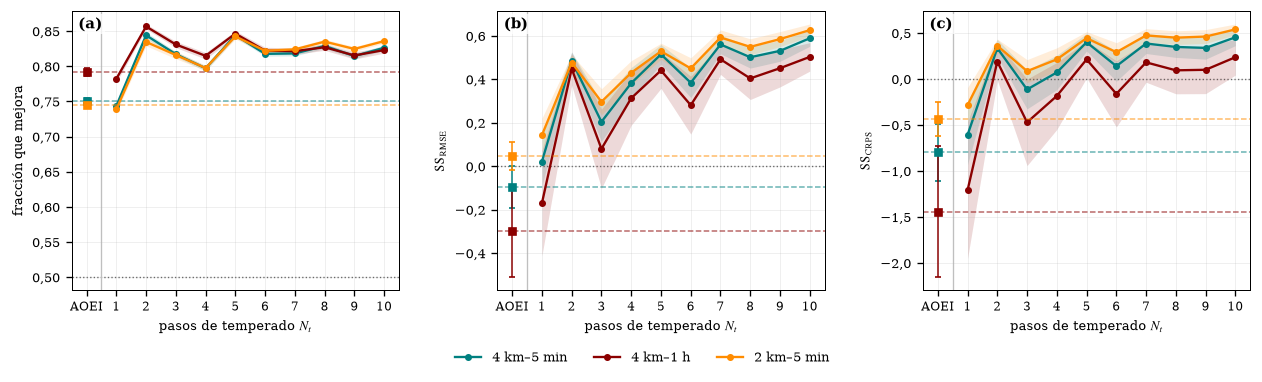

In [10]:
def draw_fig1(lang):
    V = nb.VOCAB[lang]
    fig, axes = plt.subplots(1, 3, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.44),
                             gridspec_kw={"wspace": 0.30})
    for ax, (col, ylab, guide) in zip(axes, (("F", V["frac_imp"], 0.5),
                                            ("SS_RMSE", V["ss_rmse"], 0.0),
                                            ("SS_CRPS", V["ss_crps"], 0.0))):
        ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
        ladder(ax, H1, col, DS_COLORS, label=DSL.get)
        ax.set_ylabel(ylab, fontsize=8)
        ax.set_xlabel(V["nt"], fontsize=8)
    for a, l in zip(axes, "abc"):
        nb.panel_label(a, l)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3,
               frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.13))
    return fig


nb.save(draw_fig1, "N3_fig1_headline", show=SHOW); plt.show()

In [11]:
# Un punto por miembro verdad: SS_RMSE de cada uno, con sus cuatro horas juntas.
F2 = PT1["SS_RMSE"].unstack("tm")
F2 = F2.reindex([(d, m, n) for d in DATASETS for m, n in SCHEMES])
assert F2.notna().all().all() and F2.shape[1] == len(TMS)
print("SS_RMSE por miembro verdad: mínimo, mediana y máximo entre los 60")
print(pd.DataFrame({"mín": F2.min(axis=1), "mediana": F2.median(axis=1), "máx": F2.max(axis=1),
                    "agrupado": H1.SS_RMSE.reindex(F2.index)})
      .set_axis([f"{DSL[d]} {lab(m, n)}" for d, m, n in F2.index]).to_string(float_format=lambda v: f"{v:.3f}"))

SS_RMSE por miembro verdad: mínimo, mediana y máximo entre los 60
                        mín  mediana   máx  agrupado
4 km–5 min AOEI      -0.380   -0.113 0.055    -0.097
4 km–5 min TEnKF-T1  -0.285   -0.002 0.202     0.022
4 km–5 min TEnKF-T2   0.364    0.472 0.555     0.485
4 km–5 min TEnKF-T3  -0.037    0.185 0.351     0.204
4 km–5 min TEnKF-T4   0.168    0.366 0.486     0.382
4 km–5 min TEnKF-T5   0.371    0.509 0.586     0.515
4 km–5 min TEnKF-T6   0.192    0.368 0.490     0.384
4 km–5 min TEnKF-T7   0.423    0.553 0.631     0.560
4 km–5 min TEnKF-T8   0.353    0.492 0.580     0.502
4 km–5 min TEnKF-T9   0.386    0.521 0.607     0.531
4 km–5 min TEnKF-T10  0.478    0.582 0.649     0.589
4 km–1 h AOEI        -1.046   -0.301 0.002    -0.297
4 km–1 h TEnKF-T1    -1.006   -0.171 0.157    -0.170
4 km–1 h TEnKF-T2     0.173    0.435 0.553     0.449
4 km–1 h TEnKF-T3    -0.567    0.076 0.333     0.080
4 km–1 h TEnKF-T4    -0.105    0.302 0.493     0.313
4 km–1 h TEnKF-T5     0.167    0.

figures/es/N3_fig2_by_member.png  figures/en/N3_fig2_by_member.png


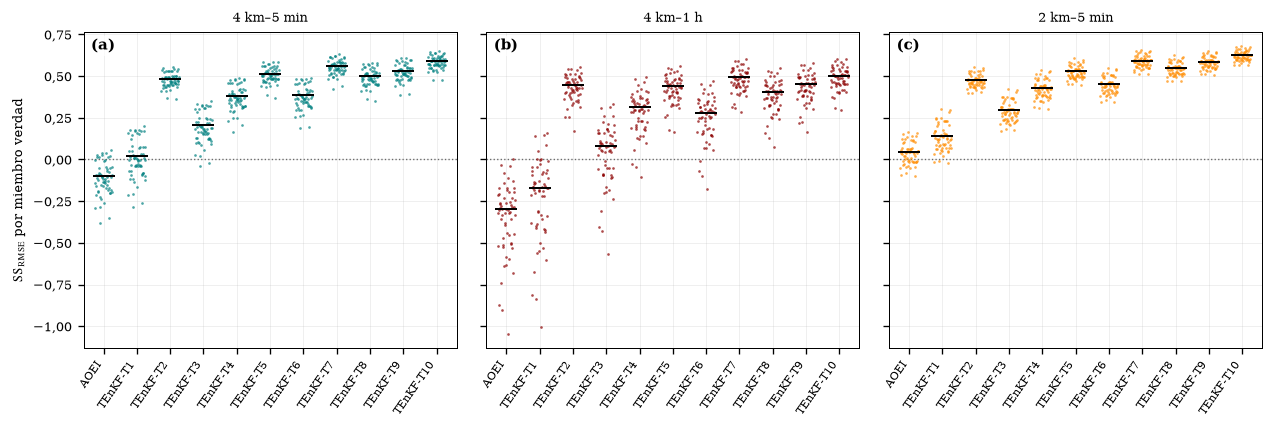

In [12]:
def draw_fig2(lang):
    fig, axes = plt.subplots(1, len(DATASETS), sharey=True, squeeze=False,
                             figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.5),
                             gridspec_kw={"wspace": 0.08})
    jit = np.linspace(-0.26, 0.26, len(TMS))
    for ax, ds in zip(axes[0], DATASETS):
        for i, (m, n) in enumerate(SCHEMES):
            y = F2.loc[(ds, m, n)].to_numpy()
            ax.plot(i + jit, y, ".", ms=3.2, color=DS_COLORS[ds], alpha=0.7, mew=0)
            ax.plot([i - .3, i + .3], [H1.loc[(ds, m, n), "SS_RMSE"]] * 2, "-", color="k", lw=1.2, zorder=5)
        ax.axhline(0, color="0.35", lw=0.8, ls=":", zorder=1)
        ax.set_xticks(range(len(SCHEMES)))
        ax.set_xticklabels([lab(*s) for s in SCHEMES], rotation=55, ha="right", fontsize=6.5)
        ax.set_xlim(-0.6, len(SCHEMES) - 0.4)
        ax.set_title(DSL[ds], fontsize=8)
    axes[0, 0].set_ylabel(LABELS[lang]["ss_rmse_truth"], fontsize=8)
    for a, l in zip(axes[0], "abc"):
        nb.panel_label(a, l)
    return fig


nb.save(draw_fig2, "N3_fig2_by_member", show=SHOW); plt.show()

In [13]:
# Observaciones con eco en la verdad y observaciones donde AOEI infla R (d² > σ_f² + R),
# sobre los experimentos asimilados: agrupado y por miembro verdad (media ± desviación).
m_ = OBS.groupby(["dataset", "tm"])[["n_points", "n_echo", "n_aoei"]].sum()
m_ = m_.assign(echo=100 * m_.n_echo / m_.n_points, aoei=100 * m_.n_aoei / m_.n_points)
pool = OBS.groupby("dataset")[["n_points", "n_echo", "n_aoei", "n_echo_aoei"]].sum()
pmt = lambda s: f"{s.mean():.2f} ± {s.std():.2f}"
print(pd.DataFrame({
    "experimentos": pool.n_points,
    "eco agrupado [%]": 100 * pool.n_echo / pool.n_points,
    "eco por miembro [%]": m_.groupby("dataset").echo.agg(pmt),
    "AOEI agrupado [%]": 100 * pool.n_aoei / pool.n_points,
    "AOEI por miembro [%]": m_.groupby("dataset").aoei.agg(pmt),
    "P(AOEI | eco) [%]": 100 * pool.n_echo_aoei / pool.n_echo,
}).rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}"))

            experimentos  eco agrupado [%] eco por miembro [%]  AOEI agrupado [%] AOEI por miembro [%]  P(AOEI | eco) [%]
dataset                                                                                                                  
4 km–5 min       2189088             10.80        10.81 ± 2.01               9.51          9.51 ± 1.60              62.96
4 km–1 h          942335              5.88         5.88 ± 1.37               8.61          8.61 ± 1.17              68.76
2 km–5 min       7537603             14.11        14.11 ± 2.45              10.84         10.84 ± 1.76              58.70


## 2 · Respuesta a las condiciones del prior

Los bins guardados son los finos (2 dBZ, 0,25, un miembro); se agrupan de a `REBIN` sobre una grilla fija, con los mismos bordes en los tres datasets: 4 dBZ desde −30 dBZ, 0,5 desde 0, y 6 miembros desde 1 (1–6, 7–12, …, 55–59). Esquemas TEnKF-T1 y TEnKF-T2.

En la fila superior el eje de $\mathrm{SS}_\mathrm{RMSE}$ va de −1 a 1 en los tres paneles. Los bins por debajo de −1 se marcan con un triángulo en el borde inferior (lleno para T1, vacío para T2), desplazado dentro del bin para que no se tapen; sus valores se imprimen abajo para la leyenda.

In [14]:
REBIN = {"dep_b": 2, "norm_innov": 2, "n_active_f_point": 6}
CURVE_SCHEMES = (("TEnKF", 1), ("TEnKF", 2))
PRED_ORDER = ("dep_b", "norm_innov", "n_active_f_point")
LS = {1: "-", 2: "--"}


# Primer borde fino de la grilla gruesa. N_Z>0 = 0 no existe (el control de calidad pide
# al menos un miembro con eco), así que sus bins gruesos empiezan en 1 miembro: 1–6, 7–12, …
COARSE_ORIGIN = {"dep_b": 0, "norm_innov": 0, "n_active_f_point": 1}


def coarsen(b, factor):
    """Bins finos agrupados de a `factor` sobre una grilla fija, la misma en los tres datasets."""
    out = []
    for p, g in b.groupby("predictor"):
        e, k, o = EDGES[p], factor[p], COARSE_ORIGIN[p]
        i = np.searchsorted(e, g.bin_left.to_numpy() + 1e-9) - 1
        assert (i >= o).all(), f"{p}: bins por debajo del origen de la grilla gruesa"
        c = (i - o) // k
        out.append(g.assign(bin_left=e[o + c * k], bin_right=e[np.minimum(o + (c + 1) * k, len(e) - 1)]))
    return pd.concat(out)


def binned(b, keys):
    """Valor central y banda por bin, con los umbrales N_MIN_BIN y N_MIN_TRUTH."""
    kb = keys + ["bin_left", "bin_right"]
    t, pt = central_band(b, kb, n_min_truth=N_MIN_TRUTH)
    t["drawn"] = t.N >= N_MIN_BIN
    t["truths_out"] = len(TMS) - t.n_truths.fillna(0).astype(int)
    for c in STATS:                        # sin banda con menos de dos miembros
        t.loc[t.n_truths.fillna(0) < 2, f"{c}_sd"] = np.nan
    return t.sort_index()


SS_LIM = (-1.0, 1.0)     # eje de SS_RMSE de la fila superior de la figura 3, el mismo en los tres paneles
SS_FLOOR = SS_LIM[0]
FLOOR_DODGE = 0.15       # separación entre triángulos de series distintas, en anchos de bin
B3 = coarsen(BINS[(BINS["var"] == "obs") & BINS.method.eq("TEnKF") & BINS.ntemp.isin([1, 2])], REBIN)
T3 = binned(B3, ["dataset", "method", "ntemp", "predictor"])
tot = T3.groupby(level=["dataset", "method", "ntemp", "predictor"]).N.transform("sum")
T3["share"] = T3.N / tot
r = T3.reset_index()
print(f"N_MIN_BIN = {N_MIN_BIN}: bins fuera de la figura, de {len(r)}:")
print(r[~r.drawn].groupby(["predictor", "dataset", "ntemp"]).size().unstack(["dataset", "ntemp"])
      .fillna(0).astype(int).rename(columns=DSL, level=0).to_string())
print(f"\nN_MIN_TRUTH = {N_MIN_TRUTH}: miembros verdad fuera de la banda, sumados sobre los bins dibujados:")
print(r[r.drawn].groupby(["predictor", "dataset", "ntemp"]).truths_out.sum().unstack(["dataset", "ntemp"])
      .rename(columns=DSL, level=0).to_string())
print(f"\nbins dibujados con menos de {N_MIN_BIN} experimentos que cambian:",
      int((r.drawn & (r.n_change < N_MIN_BIN)).sum()))

# Fila superior: el eje va de SS_LIM[0] a SS_LIM[1] en los tres paneles; los bins por debajo
# van como triángulos en el borde. El mínimo de SS_RMSE por panel, dataset y esquema, para la
# leyenda de la figura.
a3 = r[r.drawn]
g3 = a3.groupby(["predictor", "dataset", "ntemp"], sort=False)
mins = a3.loc[g3.SS_RMSE.idxmin()]
assert (a3.SS_RMSE <= SS_LIM[1]).all(), "un bin por encima del eje"
print(f"\nfila superior, SS_RMSE por bin: mínimo y bins por debajo de {SS_FLOOR:g}")
print(pd.DataFrame({"panel": mins.predictor.map(dict(zip(PRED_ORDER, "abc"))).values,
                    "dataset": mins.dataset.map(DSL).values,
                    "esquema": [lab(m, n) for m, n in zip(mins.method, mins.ntemp)],
                    "SS_RMSE mínimo": mins.SS_RMSE.round(3).values,
                    "bin": [f"[{lo:g}, {hi:g})" for lo, hi in zip(mins.bin_left, mins.bin_right)],
                    f"bins < {SS_FLOOR:g}": g3.SS_RMSE.apply(lambda v: int((v < SS_FLOOR).sum())).values,
                    }).sort_values(["panel", "dataset", "esquema"], key=lambda c: c.map(
                        {DSL[d]: i for i, d in enumerate(DATASETS)}) if c.name == "dataset" else c)
      .to_string(index=False))

N_MIN_BIN = 200: bins fuera de la figura, de 220:
dataset          4 km–5 min    4 km–1 h   
ntemp                     1  2        1  2
predictor                                 
dep_b                     1  1        4  4
n_active_f_point          0  0        1  1

N_MIN_TRUTH = 20: miembros verdad fuera de la banda, sumados sobre los bins dibujados:
dataset          4 km–5 min      4 km–1 h      2 km–5 min    
ntemp                     1    2        1    2          1   2
predictor                                                    
dep_b                   124  124       51   51         51  51
n_active_f_point          0    0      120  120          0   0
norm_innov                0    0       82   82          0   0

bins dibujados con menos de 200 experimentos que cambian: 0

fila superior, SS_RMSE por bin: mínimo y bins por debajo de -1
panel    dataset  esquema  SS_RMSE mínimo          bin  bins < -1
    a 4 km–5 min TEnKF-T1          -4.177       [2, 6)          2
    a 4 km–5 min T

figures/es/N3_fig3_predictors.png  figures/en/N3_fig3_predictors.png


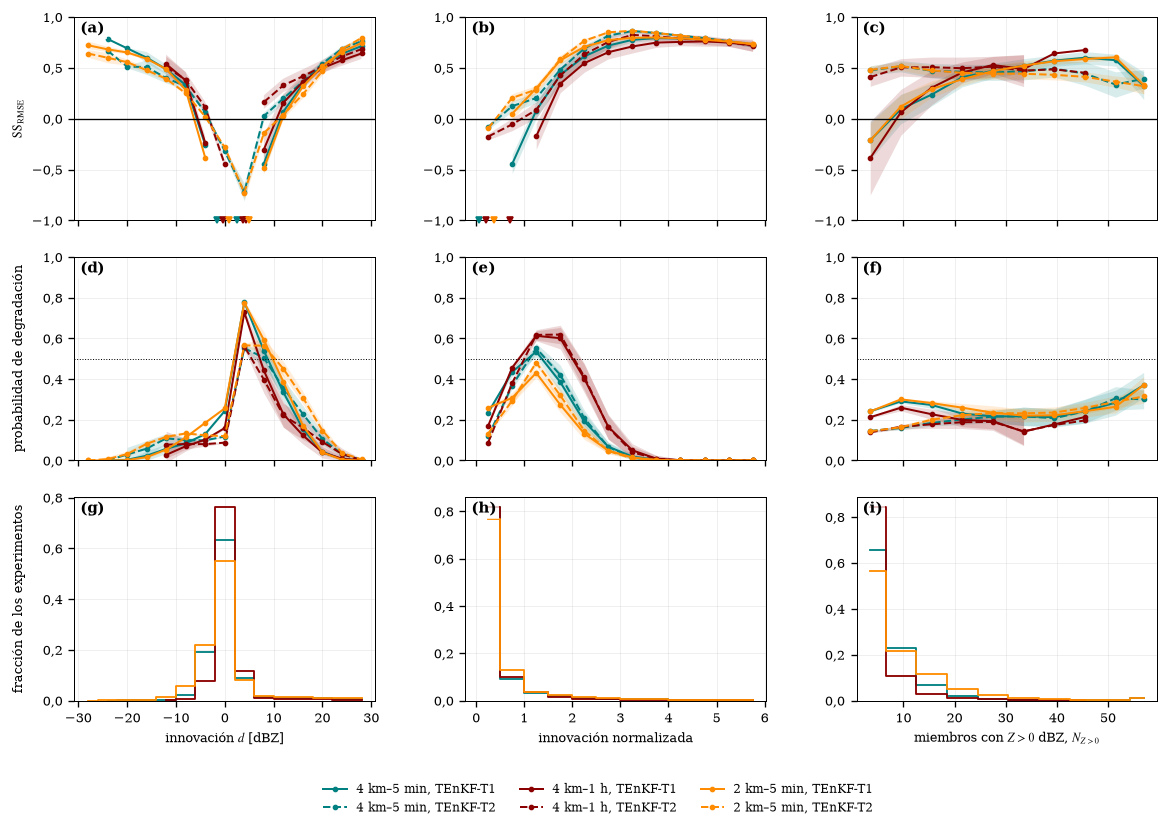

In [15]:
def draw_fig3(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    xl = {"dep_b": V["innov"], "norm_innov": L["norm_innov"], "n_active_f_point": L["n_active"]}
    fig, axes = plt.subplots(3, len(PRED_ORDER), sharex="col",
                             figsize=(nb.PAGE_W * 1.7, nb.PAGE_W * 0.36 * 3),
                             gridspec_kw={"hspace": 0.18, "wspace": 0.30})
    for cc, p in enumerate(PRED_ORDER):
        for ds in DATASETS:
            for m, n in CURVE_SCHEMES:
                d = T3.loc[(ds, m, n, p)].reset_index()
                d = d[d.drawn]
                xc = (0.5 * (d.bin_left + d.bin_right)).to_numpy()
                kw = dict(color=DS_COLORS[ds], ls=LS[n], lw=1.2)
                for row, col in ((0, "SS_RMSE"), (1, "P_deg")):
                    y, e = d[col].to_numpy(), d[f"{col}_sd"].to_numpy()
                    low = (y < SS_FLOOR) if row == 0 else np.zeros(y.size, bool)
                    yv = np.where(low, np.nan, y)
                    axes[row, cc].plot(xc, yv, marker="o", ms=2.4, **kw,
                                       label=f"{DSL[ds]}, {lab(m, n)}" if row == 0 else None)
                    axes[row, cc].fill_between(xc, yv - e, yv + e, color=DS_COLORS[ds], alpha=0.15, lw=0)
                    if low.any():
                        # una posición por serie dentro del bin, para que no se tapen
                        k_ = DATASETS.index(ds) * len(CURVE_SCHEMES) + [c[1] for c in CURVE_SCHEMES].index(n)
                        width = (d.bin_right - d.bin_left).to_numpy()[low]
                        dx = (k_ - (len(DATASETS) * len(CURVE_SCHEMES) - 1) / 2) * FLOOR_DODGE * width
                        axes[row, cc].plot(xc[low] + dx, np.full(low.sum(), SS_FLOOR), "v", ms=4.0,
                                           color=DS_COLORS[ds], mfc=DS_COLORS[ds] if n == 1 else "none",
                                           clip_on=False, zorder=6)
                if n == 1:
                    axes[2, cc].step(xc, d.share, where="mid", color=DS_COLORS[ds], lw=1.1)
        axes[0, cc].axhline(0, color="k", lw=0.8)
        axes[0, cc].set_ylim(*SS_LIM)
        axes[1, cc].axhline(0.5, color="k", lw=0.6, ls=":")
        axes[1, cc].set_ylim(0, 1)
        axes[2, cc].set_ylim(0, None)
        axes[2, cc].set_xlabel(xl[p], fontsize=7.5)
    axes[0, 0].set_ylabel(V["ss_rmse"], fontsize=7.5)
    axes[1, 0].set_ylabel(V["p_deg"], fontsize=7.5)
    axes[2, 0].set_ylabel(L["share"], fontsize=7.5)
    fig.align_ylabels(axes[:, 0])
    for a, l in zip(axes.ravel(), "abcdefghi"):
        nb.panel_label(a, l)
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center",
               bbox_to_anchor=(0.5, -0.03), ncol=len(DATASETS), fontsize=7, frameon=False)
    return fig


nb.save(draw_fig3, "N3_fig3_predictors", show=SHOW); plt.show()

## 3 · La regla de rechazo

La regla rechaza la observación si $lo \le d \le hi$. Cada experimento es una asimilación aislada, así que la regla cambia qué experimentos entran en la población.

In [16]:
RULE_MAIN = "d[0,10]"
RZ = RULE[RULE["var"] == "obs"]
H4, PT4 = central_band(RZ, ["dataset", "rule", "method", "ntemp"])
ret = (RZ.groupby(["dataset", "rule", "method", "ntemp"]).n.sum()
       / RZ[RZ.rule == "none"].groupby(["dataset", "method", "ntemp"]).n.sum())
assert (ret.groupby(level=["dataset", "rule"]).nunique() == 1).all(), "la retención depende del esquema"
H4["retained"] = ret
RET = ret.groupby(level=["dataset", "rule"]).first().unstack("rule")
print("retenidas [%]:")
print((100 * RET).rename(index=DSL)[list(RULES)].to_string(float_format=lambda v: f"{v:.1f}"))
TAB4 = {}
for rn in RULES:
    t = H4.xs(rn, level="rule")
    TAB4[rn] = pd.DataFrame({c: [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in t.iterrows()]
                             for c in ("F", "SS_RMSE", "SS_CRPS")},
                            index=pd.MultiIndex.from_tuples([(DSL[d], lab(m, n)) for d, m, n in t.index]))
TAB4 = pd.concat(TAB4, axis=1).reindex([(DSL[d], lab(*s)) for d in DATASETS for s in SCHEMES])
print("\nZ por regla: agrupado ± desviación entre los 60 miembros verdad")
print(TAB4.to_string())

retenidas [%]:
rule        none  d[0,10]  d[2,8]
dataset                          
4 km–5 min 100.0     71.9    90.6
4 km–1 h   100.0     64.0    87.9
2 km–5 min 100.0     74.5    91.1

Z por regla: agrupado ± desviación entre los 60 miembros verdad
                               none                                        d[0,10]                                        d[2,8]                                
                                  F         SS_RMSE         SS_CRPS              F        SS_RMSE         SS_CRPS              F         SS_RMSE         SS_CRPS
4 km–5 min AOEI       0.751 ± 0.005  -0.097 ± 0.097  -0.799 ± 0.309  0.873 ± 0.004  0.159 ± 0.058  -0.068 ± 0.147  0.798 ± 0.004  -0.002 ± 0.086  -0.555 ± 0.269
           TEnKF-T1   0.744 ± 0.005   0.022 ± 0.114  -0.609 ± 0.322  0.869 ± 0.004  0.329 ± 0.075   0.152 ± 0.157  0.795 ± 0.004   0.132 ± 0.103  -0.346 ± 0.280
           TEnKF-T2   0.844 ± 0.005   0.485 ± 0.042   0.336 ± 0.096  0.919 ± 0.003  0.536 ± 0.038   0.503 

figures/es/N3_fig4_rule.png  figures/en/N3_fig4_rule.png


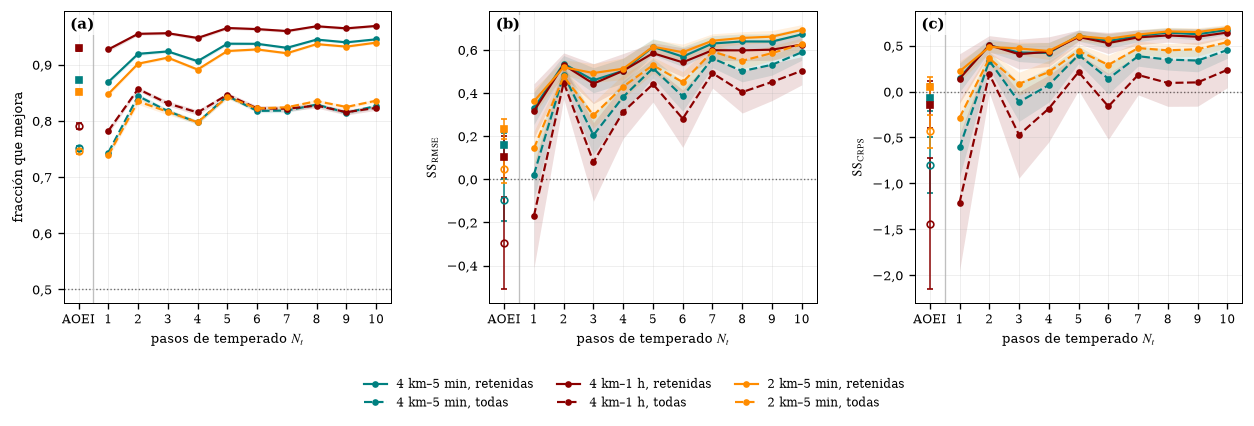

In [17]:
def draw_fig4(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(1, 3, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.46),
                             gridspec_kw={"wspace": 0.30})
    for ax, (col, ylab, guide) in zip(axes, (("F", V["frac_imp"], 0.5),
                                            ("SS_RMSE", V["ss_rmse"], 0.0),
                                            ("SS_CRPS", V["ss_crps"], 0.0))):
        ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
        for rn, ls_, mk, name in ((RULE_MAIN, "-", "s", L["retained"]), ("none", "--", "o", L["all"])):
            t = H4.xs(rn, level="rule").reset_index()
            for ds, g in t.groupby("dataset"):
                c = DS_COLORS[ds]
                te = g[g.method == "TEnKF"].sort_values("ntemp")
                ax.fill_between(te.ntemp, te[col] - te[f"{col}_sd"], te[col] + te[f"{col}_sd"],
                                color=c, alpha=0.13, lw=0)
                ax.plot(te.ntemp, te[col], ls_, marker="o", ms=3.0, color=c, lw=1.3,
                        label=f"{DSL[ds]}, {name}")
                a = g[g.method == "AOEI"]
                ax.errorbar([X_AOEI], a[col], yerr=a[f"{col}_sd"], fmt=mk, ms=4.0,
                            mfc=c if ls_ == "-" else "none", color=c, capsize=2, elinewidth=0.9, zorder=4)
        ax.axvline(X_SPLIT, color="0.75", lw=0.8, zorder=1)
        ax.set_xticks([X_AOEI] + list(NTEMP_REQ))
        ax.set_xticklabels(["AOEI"] + [str(n) for n in NTEMP_REQ], fontsize=7)
        ax.set_xlabel(V["nt"], fontsize=8)
        ax.set_ylabel(ylab, fontsize=8)
    for a, l in zip(axes, "abc"):
        nb.panel_label(a, l)
    # una columna por dataset: retenidas arriba, todas abajo
    h, l = axes[0].get_legend_handles_labels()
    order = sorted(range(len(l)), key=lambda i: ([DSL[d] for d in DATASETS].index(l[i].split(", ")[0]),
                                                 l[i].split(", ")[1] != L["retained"]))
    fig.legend([h[i] for i in order], [l[i] for i in order], loc="lower center", ncol=len(DATASETS),
               frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.20))
    return fig


nb.save(draw_fig4, "N3_fig4_rule", show=SHOW); plt.show()

## 4 · Las variables de estado

Probabilidad de degradación contra la innovación, sobre los bins finos de 2 dBZ: los límites de la regla, 0 y 10 dBZ, caen sobre bordes. Cada variable cuenta empates con su propia tolerancia.

In [18]:
assert all(np.isclose(np.abs(EDGES["dep_b"] - b), 0).any() for b in RULES[RULE_MAIN]), \
    "los límites de la regla no caen sobre bordes de bin"
B5 = BINS[(BINS.predictor == "dep_b") & BINS.method.eq("TEnKF") & BINS.ntemp.isin([1, 2])]
T5 = binned(B5, ["dataset", "var", "method", "ntemp"])
r5 = T5.reset_index()
print(f"N_MIN_BIN = {N_MIN_BIN}: bins fuera de la figura:")
print(r5[~r5.drawn].groupby(["var", "dataset", "ntemp"]).size().unstack(["dataset", "ntemp"])
      .reindex(list(BIN_VARS)).fillna(0).astype(int).rename(columns=DSL, level=0).to_string())
print(f"N_MIN_TRUTH = {N_MIN_TRUTH}: miembros fuera de la banda, sumados sobre los bins dibujados:")
print(r5[r5.drawn].groupby(["var", "dataset", "ntemp"]).truths_out.sum().unstack(["dataset", "ntemp"])
      .reindex(list(BIN_VARS)).rename(columns=DSL, level=0).to_string())
print(f"bins dibujados con menos de {N_MIN_BIN} experimentos que cambian:",
      r5[r5.drawn & (r5.n_change < N_MIN_BIN)].groupby("var").size().to_dict())

# Números de la figura para el texto, de las sumas: P_deg de un tramo = 1 − Σ n_imp / Σ n_change
# sobre sus bins. "En la banda" son los bins enteramente dentro de [0, 10]; las curvas
# cubren |d| < 30 dBZ.
LO, HI = RULES[RULE_MAIN]
D_EDGE = float(EDGES["dep_b"][-1])
B5s = B5.groupby(["dataset", "var", "method", "ntemp", "bin_left", "bin_right"])[SUMS].sum().reset_index()


def tramo(d, lo=-np.inf, hi=np.inf):
    s = d[(d.bin_left >= lo) & (d.bin_right <= hi)]
    return 1 - s.n_imp.sum() / s.n_change.sum()


def max_en_banda(d):
    s = d[(d.bin_left >= LO) & (d.bin_right <= HI)]
    r_ = (1 - s.n_imp / s.n_change).to_numpy()
    k = int(np.argmax(r_))
    return f"{r_[k]:.3f} [{s.bin_left.iloc[k]:g}, {s.bin_right.iloc[k]:g})"


rows = []
for ds in DATASETS:
    for nt in (1, 2):
        sel = lambda v: B5s[(B5s.dataset == ds) & (B5s["var"] == v) & (B5s.ntemp == nt)]
        rows.append({"dataset": DSL[ds], "esquema": lab("TEnKF", nt),
                     "Z: máx. en banda": max_en_banda(sel("obs")),
                     "qtot: máx. en banda": max_en_banda(sel("qtot")),
                     f"qtot: {HI:g} ≤ d < {D_EDGE:g}": tramo(sel("qtot"), lo=HI),
                     "w: d < 0": tramo(sel("w"), hi=0.0), "w: d ≥ 0": tramo(sel("w"), lo=0.0)})
print("\nprobabilidad de degradación (entre los que cambian), agrupada")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

N_MIN_BIN = 200: bins fuera de la figura:
dataset 4 km–5 min    4 km–1 h   
ntemp            1  2        1  2
var                              
obs              4  4        7  7
w                4  4        7  7
qtot             4  4        7  7
N_MIN_TRUTH = 20: miembros fuera de la banda, sumados sobre los bins dibujados:
dataset 4 km–5 min      4 km–1 h      2 km–5 min     
ntemp            1    2        1    2          1    2
var                                                  
obs            194  194      219  219        172  172
w              194  194      219  219        172  172
qtot           194  194      219  219        172  172
bins dibujados con menos de 200 experimentos que cambian: {}

probabilidad de degradación (entre los que cambian), agrupada
   dataset  esquema Z: máx. en banda qtot: máx. en banda  qtot: 10 ≤ d < 30  w: d < 0  w: d ≥ 0
4 km–5 min TEnKF-T1     0.801 [4, 6)        0.978 [0, 2)              0.559     0.462     0.563
4 km–5 min TEnKF-T2     0.656 [4, 

figures/es/N3_fig5_pdeg_state_vs_obs.png  figures/en/N3_fig5_pdeg_state_vs_obs.png


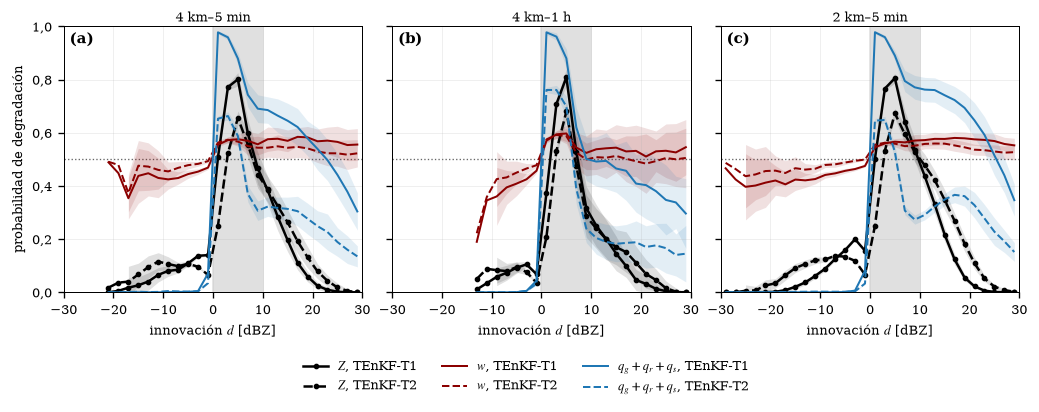

In [19]:
def draw_fig5(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    vl = {"obs": L["Z"], "w": L["w"], "qtot": L["qtot"]}
    fig, axes = plt.subplots(1, len(DATASETS), sharey=True, squeeze=False,
                             figsize=(nb.PAGE_W * 1.5, nb.PAGE_W * 0.42),
                             gridspec_kw={"wspace": 0.10})
    axes = axes[0]
    for ax, ds in zip(axes, DATASETS):
        ax.axvspan(*RULES[RULE_MAIN], color="0.88", zorder=0)
        ax.axhline(0.5, color="0.4", lw=0.8, ls=":", zorder=1)
        for v in BIN_VARS:
            for m, n in CURVE_SCHEMES:
                d = T5.loc[(ds, v, m, n)].reset_index()
                d = d[d.drawn]
                xc = 0.5 * (d.bin_left + d.bin_right)
                ax.plot(xc, d.P_deg, marker="o" if v == "obs" else None, ms=2.4,
                        lw=1.5 if v == "obs" else 1.2, ls=LS[n], color=GR_COLORS[v],
                        label=f"{vl[v]}, {lab(m, n)}")
                ax.fill_between(xc, d.P_deg - d.P_deg_sd, d.P_deg + d.P_deg_sd,
                                color=GR_COLORS[v], alpha=0.12, lw=0)
        ax.set_xlabel(V["innov"], fontsize=8)
        ax.set_title(DSL[ds], fontsize=8, pad=3)
        ax.set_ylim(0, 1)
        ax.set_xlim(EDGES["dep_b"][0], EDGES["dep_b"][-1])
    axes[0].set_ylabel(V["p_deg"], fontsize=8)
    for a, l in zip(axes, "abc"):
        nb.panel_label(a, l)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center",
               bbox_to_anchor=(0.5, -0.22), ncol=len(BIN_VARS), frameon=False, fontsize=7.5)
    return fig


nb.save(draw_fig5, "N3_fig5_pdeg_state_vs_obs", show=SHOW); plt.show()

In [20]:
# La figura 1 para w y q_g+q_r+q_s: fracción que mejora y SS_RMSE (el CRPS de la suma de
# hidrometeoros no está en los archivos).
H6 = {g: central_band(BASE[BASE["var"] == g], ["dataset", "method", "ntemp"])[0] for g in ("w", "qtot")}
for g, t in H6.items():
    assert (t.n_truths == len(TMS)).all()
    print(f"\n{g}: agrupado ± desviación entre los 60 miembros verdad")
    print(pd.DataFrame({c: [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in t.iterrows()] for c in ("F", "SS_RMSE")},
                       index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in t.index]).to_string())


w: agrupado ± desviación entre los 60 miembros verdad
                                  F         SS_RMSE
4 km–5 min AOEI       0.509 ± 0.004   0.003 ± 0.005
4 km–5 min TEnKF-T1   0.504 ± 0.005  -0.034 ± 0.042
4 km–5 min TEnKF-T2   0.487 ± 0.004  -0.086 ± 0.054
4 km–5 min TEnKF-T3   0.489 ± 0.004  -0.038 ± 0.041
4 km–5 min TEnKF-T4   0.485 ± 0.004  -0.096 ± 0.059
4 km–5 min TEnKF-T5   0.480 ± 0.004  -0.090 ± 0.060
4 km–5 min TEnKF-T6   0.482 ± 0.004  -0.082 ± 0.058
4 km–5 min TEnKF-T7   0.481 ± 0.004  -0.108 ± 0.069
4 km–5 min TEnKF-T8   0.482 ± 0.004  -0.082 ± 0.061
4 km–5 min TEnKF-T9   0.483 ± 0.004  -0.088 ± 0.062
4 km–5 min TEnKF-T10  0.483 ± 0.004  -0.082 ± 0.059
4 km–1 h AOEI         0.503 ± 0.005   0.002 ± 0.012
4 km–1 h TEnKF-T1     0.499 ± 0.005  -0.061 ± 0.142
4 km–1 h TEnKF-T2     0.485 ± 0.004  -0.162 ± 0.193
4 km–1 h TEnKF-T3     0.489 ± 0.005  -0.059 ± 0.110
4 km–1 h TEnKF-T4     0.486 ± 0.004  -0.139 ± 0.207
4 km–1 h TEnKF-T5     0.482 ± 0.004  -0.124 ± 0.190
4 km–1 h 

figures/es/N3_fig6_state_headline.png  figures/en/N3_fig6_state_headline.png


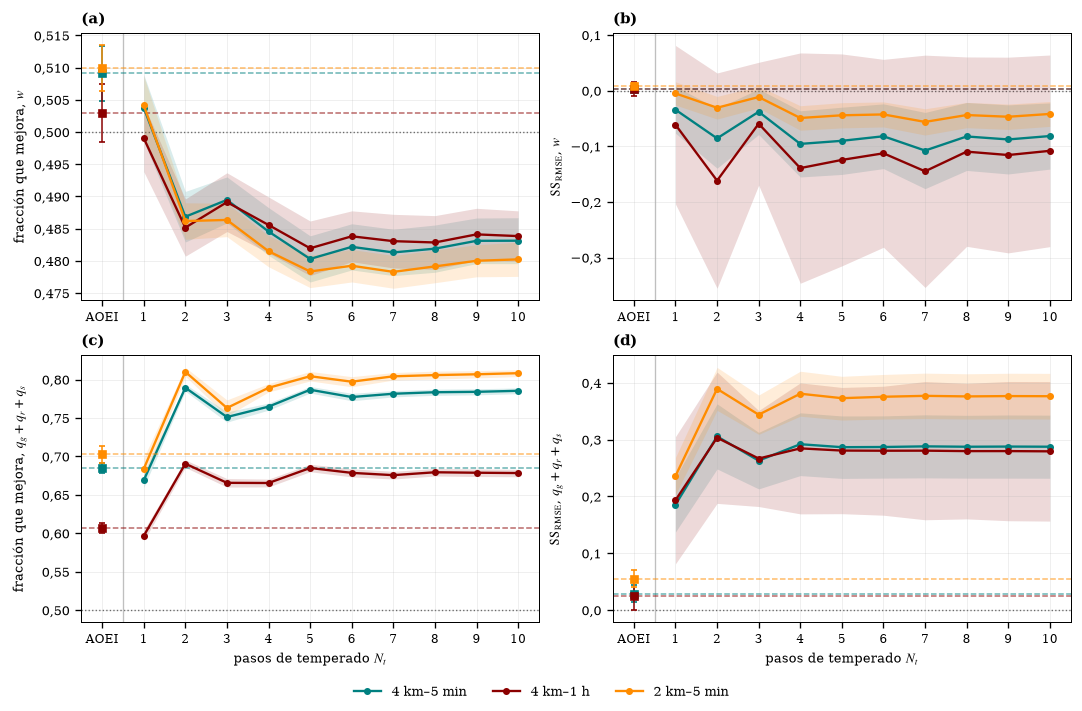

In [21]:
def draw_fig6(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(2, 2, figsize=(nb.PAGE_W * 1.3, nb.PAGE_W * 0.85),
                             constrained_layout=True)
    for r_, g in enumerate(("w", "qtot")):
        for c_, (col, ylab, guide) in enumerate((("F", V["frac_imp"], 0.5), ("SS_RMSE", V["ss_rmse"], 0.0))):
            ax = axes[r_, c_]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            ladder(ax, H6[g], col, DS_COLORS, label=DSL.get)
            ax.set_ylabel(f"{ylab}, {L[g]}", fontsize=8)
            if r_ == 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcd"):       # fuera del panel: AOEI ocupa la esquina
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3,
               frameon=False, fontsize=8)
    return fig


nb.save(draw_fig6, "N3_fig6_state_headline", show=SHOW); plt.show()

In [22]:
# Las nueve variables de estado para TEnKF-T1, TEnKF-T2 y AOEI, en todos los datasets:
# agrupado (desviación entre los 60 miembros). SS_CRPS solo para las 8 variables del
# modelo; la razón de dispersión es sqrt(Σσ_a² / Σσ_f²) en la celda observada.
TABLE_SCHEMES = (("TEnKF", 1), ("TEnKF", 2), ("AOEI", 1))
HS, _ = central_band(BASE[BASE["var"] != "obs"], ["dataset", "var", "method", "ntemp"])
fmt_ = lambda c, s: "—" if not np.isfinite(c) else f"{c:.3f} ({s:.3f})"
rows = []
for ds in DATASETS:
    for v in STATE + ("qtot",):
        for m, n in TABLE_SCHEMES:
            r_ = HS.loc[(ds, v, m, n)]
            rows.append({"dataset": DSL[ds], "variable": v, "esquema": lab(m, n),
                         **{c: fmt_(r_[c], r_[f"{c}_sd"]) for c in ("F", "SS_RMSE", "SS_CRPS", "spread_ratio")}})
TAB_STATE = pd.DataFrame(rows).rename(columns={"spread_ratio": "dispersión a/f"})
for ds in DATASETS:
    print(f"\n{DSL[ds]}")
    print(TAB_STATE[TAB_STATE.dataset == DSL[ds]].drop(columns="dataset").to_string(index=False))


4 km–5 min
variable  esquema             F        SS_RMSE        SS_CRPS dispersión a/f
      qg TEnKF-T1 0.659 (0.017)  0.133 (0.060) -0.244 (0.149)  0.562 (0.005)
      qg TEnKF-T2 0.799 (0.011)  0.258 (0.070)  0.301 (0.053)  0.390 (0.013)
      qg     AOEI 0.674 (0.013)  0.020 (0.015) -0.232 (0.095)  0.597 (0.019)
      qr TEnKF-T1 0.674 (0.012)  0.138 (0.055) -0.137 (0.117)  0.572 (0.005)
      qr TEnKF-T2 0.803 (0.007)  0.254 (0.073)  0.340 (0.047)  0.389 (0.012)
      qr     AOEI 0.691 (0.009)  0.026 (0.018) -0.171 (0.072)  0.608 (0.016)
      qs TEnKF-T1 0.654 (0.021)  0.148 (0.578) -0.151 (1.014)  0.582 (0.007)
      qs TEnKF-T2 0.761 (0.017)  0.211 (0.382)  0.129 (0.527)  0.443 (0.018)
      qs     AOEI 0.666 (0.020)  0.029 (0.074) -0.152 (0.395)  0.616 (0.021)
       T TEnKF-T1 0.524 (0.023)  0.042 (0.017)  0.027 (0.011)  0.940 (0.000)
       T TEnKF-T2 0.520 (0.025)  0.033 (0.014)  0.018 (0.009)  0.943 (0.000)
       T     AOEI 0.530 (0.023)  0.014 (0.008)  0.010 (0.004)  0

In [23]:
# q_s por la microfísica del miembro verdad, el mismo corte que N4 (sección 6). La namelist
# del miembro m es m mod 6 + 1; WSM6 en las namelists 1–3, Lin en 4–6: 30 miembros verdad
# en cada grupo. Las definiciones son las de todo N3: SS sobre las sumas de la población del
# grupo, F entre los que cambian (empate de q_s: TOLS["qs"] = 1e-7 kg/kg), banda = ±1
# desviación entre los 30 miembros del grupo, cada uno con sus cuatro horas. q_g y q_r como
# control. "SS > 0" cuenta los miembros del grupo con el SS de su población positivo.
NAMELIST = lambda m: m % 6 + 1
MICRO = lambda m: "WSM6" if NAMELIST(m) <= 3 else "Lin"
MP_GROUPS = ("WSM6", "Lin")
MP_SCHEMES = (("AOEI", 1), ("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5))
MP_KEYS = ["dataset", "var", "micro", "method", "ntemp"]
assert TOLS["qs"] == 1e-7
BM = BASE[BASE["var"].isin(["qs", "qg", "qr"])].assign(micro=lambda d: d.tm.map(MICRO))
assert (BM.groupby("micro").tm.nunique() == 30).all(), "30 miembros verdad por microfísica"
HM, PTM = central_band(BM, MP_KEYS)
assert (HM.n_truths == 30).all()
SGN = pd.DataFrame({"rmse": PTM.SS_RMSE > 0, "crps": PTM.SS_CRPS > 0,
                    "ambos": (PTM.SS_RMSE > 0) & (PTM.SS_CRPS > 0)}).groupby(level=MP_KEYS).sum()

for v in ("qs", "qg", "qr"):
    rows = []
    for ds in DATASETS:
        for mp in MP_GROUPS:
            for m, n in MP_SCHEMES:
                k = (ds, v, mp, m, n)
                r_, s_ = HM.loc[k], SGN.loc[k]
                row = {"dataset": DSL[ds], "microfísica": mp, "esquema": lab(m, n),
                       "SS_RMSE": pm(r_.SS_RMSE, r_.SS_RMSE_sd), "SS_CRPS": pm(r_.SS_CRPS, r_.SS_CRPS_sd)}
                if v == "qs":
                    row["F"] = pm(r_.F, r_.F_sd)
                row |= {"SS_RMSE > 0": f"{s_.rmse}/30", "SS_CRPS > 0": f"{s_.crps}/30", "los dos > 0": f"{s_.ambos}/30"}
                rows.append(row)
    print(f"\n{v} por microfísica del miembro verdad: agrupado ± desviación entre los 30 miembros del grupo")
    print(pd.DataFrame(rows).to_string(index=False))

# La escala: el RMSE del prior de q_s, agrupado por grupo (el mismo en todos los esquemas).
pr = HM.xs("qs", level="var").RMSE_f
assert (pr.groupby(level=["dataset", "micro"]).nunique() == 1).all(), "el prior no depende del esquema"
pr = 1e3 * pr.groupby(level=["dataset", "micro"]).first().unstack("micro")[list(MP_GROUPS)]
pr["WSM6 / Lin"] = pr.WSM6 / pr.Lin
pr.index = [DSL[d] for d in pr.index]
print("\nRMSE del prior de q_s en la celda observada, agrupado por microfísica [g/kg]")
print(pr.to_string(float_format=lambda x: f"{x:.4f}"))


qs por microfísica del miembro verdad: agrupado ± desviación entre los 30 miembros del grupo
   dataset microfísica  esquema        SS_RMSE        SS_CRPS             F SS_RMSE > 0 SS_CRPS > 0 los dos > 0
4 km–5 min        WSM6     AOEI  0.034 ± 0.011 -0.038 ± 0.056 0.683 ± 0.008       30/30        1/30        1/30
4 km–5 min        WSM6 TEnKF-T1  0.226 ± 0.033  0.149 ± 0.078 0.671 ± 0.010       30/30       27/30       27/30
4 km–5 min        WSM6 TEnKF-T2  0.253 ± 0.038  0.281 ± 0.030 0.775 ± 0.009       30/30       30/30       30/30
4 km–5 min        WSM6 TEnKF-T5  0.224 ± 0.036  0.238 ± 0.028 0.769 ± 0.008       30/30       30/30       30/30
4 km–5 min         Lin     AOEI -0.062 ± 0.079 -0.794 ± 0.137 0.649 ± 0.013        7/30        0/30        0/30
4 km–5 min         Lin TEnKF-T1 -0.894 ± 0.236 -1.851 ± 0.225 0.636 ± 0.015        0/30        0/30        0/30
4 km–5 min         Lin TEnKF-T2 -0.438 ± 0.253 -0.731 ± 0.198 0.748 ± 0.012        1/30        0/30        0/30
4 km–5 min

## 5 · El experimento de pesos

A a las 19 UTC, $N_t \in \{3, 5\}$ × $\alpha_s \in \{1;\ 0{,}25\}$. Subir $N_t$ con $\alpha_s = 1$ agrega pasos y a la vez reparte el peso de forma más pareja; bajar $\alpha_s$ a $N_t$ fijo solo hace lo segundo.

In [24]:
from da.core import tempering_schedule

print(WRUNS[["alpha_s", "tag", "id_source", "stride", "loc_x", "R", "dbz_min", "n_files"]].to_string(index=False), "\n")
sched = []
for nt, a in W_CELLS:
    w_ = tempering_schedule(nt, a).astype(float)
    assert len(w_) == nt and np.isclose(w_.sum(), 1.0)
    sched.append({"esquema": f"TEnKF-T{nt}, α_s = {a:g}", "pesos": ", ".join(f"{x:.3f}" for x in w_),
                  "último": w_[-1], "todos salvo los dos últimos": w_[:-2].sum()})
print(pd.DataFrame(sched).to_string(index=False, float_format=lambda v: f"{v:.3f}"), "\n")

WZ = WB[(WB["var"] == "obs") & (WB.method == "TEnKF") & WB.ntemp.isin([3, 5])]
H7, PT7 = central_band(WZ, ["ntemp", "alpha_s"])
for c in ("F", "SS_RMSE", "SS_CRPS"):
    print(f"{c}: agrupado ± desviación entre los 60 miembros verdad")
    print(H7.apply(lambda r_: pm(r_[c], r_[f"{c}_sd"]), axis=1).unstack("alpha_s")
          .rename(index=lambda n: f"Nt = {n}", columns=lambda a: f"α_s = {a:g}").to_string(), "\n")

P7 = PT7["SS_RMSE"].unstack(["ntemp", "alpha_s"])

 alpha_s                                  tag       id_source  stride  loc_x   R  dbz_min  n_files
    1.00        WS_A_sweep_1900_LOC0.1_ALLMEM H(x) del subset      10    0.1 5.0      0.0       60
    0.25 WS_A_sweep_1900_LOC0.1_ALLMEM_AS0.25      dataset_id      10    0.1 5.0      0.0       60 

             esquema                             pesos  último  todos salvo los dos últimos
   TEnKF-T3, α_s = 1               0.044, 0.324, 0.632   0.632                        0.044
TEnKF-T3, α_s = 0.25               0.218, 0.359, 0.424   0.424                        0.218
   TEnKF-T5, α_s = 1 0.003, 0.070, 0.190, 0.313, 0.423   0.423                        0.264
TEnKF-T5, α_s = 0.25 0.082, 0.173, 0.222, 0.252, 0.271   0.271                        0.477 

F: agrupado ± desviación entre los 60 miembros verdad
alpha_s     α_s = 0.25        α_s = 1
ntemp                                
Nt = 3   0.772 ± 0.005  0.818 ± 0.005
Nt = 5   0.786 ± 0.005  0.842 ± 0.005 

SS_RMSE: agrupado ± desviación 

In [25]:
# Los cuatro contrastes: más pasos a α_s fijo y pesos más parejos a Nt fijo. Para cada
# estadístico, la diferencia agrupada y cuántos de los 60 miembros verdad tienen cada signo.
CONTRASTS = ((((5, 1.0), (3, 1.0)), "T5 − T3, α_s = 1"),
             (((5, 0.25), (3, 0.25)), "T5 − T3, α_s = 0,25"),
             (((3, 0.25), (3, 1.0)), "α_s 0,25 − 1, Nt = 3"),
             (((5, 0.25), (5, 1.0)), "α_s 0,25 − 1, Nt = 5"))
rows = []
for (k1, k2), name in CONTRASTS:
    r_ = {"contraste": name}
    for c in ("F", "SS_RMSE", "SS_CRPS"):
        pt = PT7[c].unstack(["ntemp", "alpha_s"])
        dd = (pt[k1] - pt[k2]).to_numpy()
        assert dd.size == len(TMS)
        r_[(c, "Δ agrupado")] = f"{H7.loc[k1, c] - H7.loc[k2, c]:+.4f}"
        r_[(c, "+")], r_[(c, "−")], r_[(c, "0")] = int((dd > 0).sum()), int((dd < 0).sum()), int((dd == 0).sum())
    rows.append(r_)
TAB7 = pd.DataFrame(rows).set_index("contraste")
TAB7.columns = pd.MultiIndex.from_tuples(TAB7.columns)
print("Contrastes: diferencia agrupada y signo por miembro verdad (de 60)")
print(TAB7.to_string())

Contrastes: diferencia agrupada y signo por miembro verdad (de 60)
                              F               SS_RMSE               SS_CRPS           
                     Δ agrupado   +   −  0 Δ agrupado   +   −  0 Δ agrupado   +   −  0
contraste                                                                             
T5 − T3, α_s = 1        +0.0244  60   0  0    +0.3060  60   0  0    +0.4954  60   0  0
T5 − T3, α_s = 0,25     +0.0137  60   0  0    +0.1950  60   0  0    +0.3371  60   0  0
α_s 0,25 − 1, Nt = 3    -0.0456   0  60  0    +0.0156  55   5  0    -0.0872   0  60  0
α_s 0,25 − 1, Nt = 5    -0.0562   0  60  0    -0.0954   0  60  0    -0.2454   0  60  0


In [26]:
# α_s 0,25 contra 1 con Nt = 3: ¿los pesos más parejos ganan en los errores grandes del prior
# y pierden en los chicos? Mitades por la mediana agrupada de |e_f| (la misma en las dos
# corridas: el prior es el mismo).
S3 = WS[WS.ntemp == 3]
whole = derive(WZ[WZ.ntemp == 3].groupby("alpha_s")[SUMS].sum())
halves, _ = central_band(S3, ["half", "alpha_s"])
print(f"mediana de |e_f| = {WS.median_ef.iloc[0]:.4f} dBZ")
print(pd.DataFrame({"RMSE_f [dBZ]": whole.RMSE_f, "RMSE_a [dBZ]": whole.RMSE_a, "SS_RMSE": whole.SS_RMSE,
                    "F": whole.F}).rename(index=lambda a: f"α_s = {a:g}").to_string(float_format=lambda v: f"{v:.4f}"))
t = halves.reset_index()
t = pd.DataFrame({"mitad de |e_f|": t.half, "α_s": t.alpha_s.map(lambda a: f"{a:g}"), "N": t.N.astype(int),
                  "F": [pm(c, s, 4) for c, s in zip(t.F, t.F_sd)],
                  "RMSE_f [dBZ]": t.RMSE_f.round(4), "RMSE_a [dBZ]": t.RMSE_a.round(4),
                  "SS_RMSE": [pm(c, s, 4) for c, s in zip(t.SS_RMSE, t.SS_RMSE_sd)]})
print("\npor mitad (agrupado ± desviación entre los 60 miembros verdad):")
print(t.sort_values(["mitad de |e_f|", "α_s"], ascending=[True, False]).to_string(index=False))
dF = halves.F.unstack("alpha_s")
print("\nF(α_s 0,25) − F(α_s 1): " + ", ".join(f"{h}: {dF.loc[h, 0.25] - dF.loc[h, 1.0]:+.4f}" for h in ("debajo", "encima")))

mediana de |e_f| = 1.2763 dBZ
            RMSE_f [dBZ]  RMSE_a [dBZ]  SS_RMSE      F
alpha_s                                               
α_s = 0.25        6.8210        5.2637   0.2283 0.7723
α_s = 1           6.8210        5.3702   0.2127 0.8179

por mitad (agrupado ± desviación entre los 60 miembros verdad):
mitad de |e_f|  α_s      N               F  RMSE_f [dBZ]  RMSE_a [dBZ]          SS_RMSE
        debajo    1 269639 0.8218 ± 0.0064        0.6311        3.0372 -3.8130 ± 0.2036
        debajo 0.25 269639 0.7824 ± 0.0069        0.6311        2.8673 -3.5437 ± 0.1829
        encima    1 269540 0.8142 ± 0.0069        9.6266        6.9614  0.2769 ± 0.0926
        encima 0.25 269540 0.7628 ± 0.0083        9.6266        6.8702  0.2863 ± 0.0992

F(α_s 0,25) − F(α_s 1): debajo: -0.0394, encima: -0.0514


figures/es/N3_fig7_weights.png  figures/en/N3_fig7_weights.png


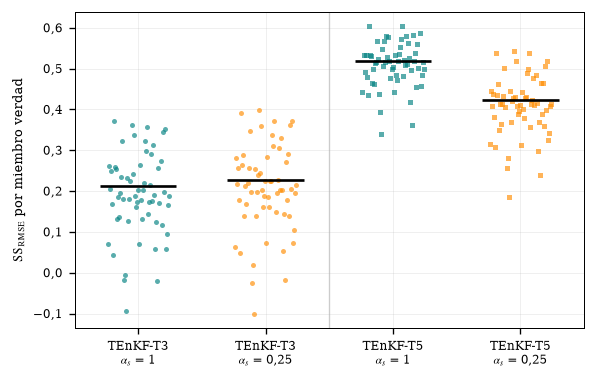

In [27]:
W_COL = {1.0: nb.C_NT1, 0.25: nb.C_NONE}
W_MRK = {3: "o", 5: "s"}


def draw_fig7(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, ax = plt.subplots(figsize=(nb.PAGE_W * 0.8, nb.PAGE_W * 0.5))
    jit = np.linspace(-0.24, 0.24, len(TMS))
    for x, (nt, a) in enumerate(W_CELLS):
        v = P7[(nt, a)].to_numpy(float)
        ax.plot(x + jit, v, W_MRK[nt], ms=3.0, mew=0, alpha=0.65, color=W_COL[a], zorder=3)
        ax.hlines(H7.loc[(nt, a), "SS_RMSE"], x - 0.3, x + 0.3, color="k", lw=1.6, zorder=5)
    ax.axvline(1.5, color="0.8", lw=0.8, zorder=0)
    ax.set_xticks(range(len(W_CELLS)))
    ax.set_xticklabels([f"{lab('TEnKF', nt)}\n{L['alpha_s']} = {nb.fmt(a, lang)}" for nt, a in W_CELLS],
                       fontsize=7)
    ax.set_xlim(-0.5, len(W_CELLS) - 0.5)
    ax.set_ylabel(L["ss_rmse_truth"], fontsize=8)
    ax.tick_params(labelsize=7)
    return fig


nb.save(draw_fig7, "N3_fig7_weights", show=SHOW); plt.show()

## 6 · Verificación condicionada al movimiento vertical fuerte

Los mismos experimentos (A, B y C, las cuatro horas, celdas del barrido, sin regla de rechazo) en cuatro poblaciones, según la verdad en la celda observada:

- $w_t \ge$ 15 m/s y $w_t \le$ −8 m/s, los umbrales de los puntos de corriente vertical fuerte de N3_Step_by_step; en las celdas del barrido hay pocos experimentos así, y se imprimen los tamaños;
- núcleo de tormenta: $Z_t >$ 40 dBZ en la celda (sin la condición sobre las vecinas de N3_Step_by_step);
- todas las celdas, la población de la sección 1, como referencia.

Para $Z$ y $w$, con TEnKF-T1, T2, T5 y AOEI: $\mathrm{SS_{RMSE}}$, $\mathrm{SS_{CRPS}}$ y $F$, con las definiciones y tolerancias de la sección 0. Valor central: la población agrupada; banda: ±1 desviación estándar del estadístico por miembro verdad (sus cuatro horas juntas), solo con los miembros que tienen al menos `N_MIN_TRUTH` experimentos en la población (como en los gráficos por bin). Solo tablas. Las sumas se guardan en `data/derived/N3/N3_sums_cond.csv`; se rehacen con `REBUILD` o si faltan, y la población «todas» tiene que dar las sumas de `N3_sums_base.csv`.

In [28]:
COND_FILE = OUT / f"{PREFIX}_cond.csv"
W_UP_C, W_DOWN_C, Z_CORE_C = 15.0, -8.0, 40.0
CONDS_C = ("w ≥ 15", "w ≤ −8", "Z_t > 40", "todas")
SCHEMES_C = (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1))
VARS_C = ("obs", "w")


def truth_w_ref(f):
    """w de la verdad en el orden de las filas de read_file: las de un esquema, ordenadas por celda."""
    with np.load(f) as z:
        meth, nt = z["method"].astype(str), z["ntemp"].astype(int)
        i, j, k, tw = z["i"], z["j"], z["k"], z["truth_point_w"]
    key = np.ravel_multi_index((i, j, k), tuple(int(a.max()) + 1 for a in (i, j, k)))
    first = sorted(set(zip(meth, nt)), key=scheme_order)[0]
    r = np.flatnonzero((meth == first[0]) & (nt == first[1]))
    return tw[r[np.argsort(key[r], kind="stable")]].astype(float)


def build_cond():
    R = float(RUNS.R.iloc[0])
    rows, t0 = [], time.time()
    for ds in DATASETS:
        for hh in HOURS:
            for tm in TMS:
                f = nb.sweep_files(run_of(ds, hh), [tm])[0]
                schemes, err, pred, obs = read_file(f, R)
                assert [lab(*c) for c in schemes] == ["AOEI"] + [f"TEnKF-T{n}" for n in NTEMP_REQ]
                wt, zt = truth_w_ref(f), obs["yo_clean"]
                masks = {"w ≥ 15": wt >= W_UP_C, "w ≤ −8": wt <= W_DOWN_C, "Z_t > 40": zt > Z_CORE_C,
                         "todas": np.ones(zt.size, bool)}
                for sc in schemes:
                    for v in VARS_C:
                        for cn, m in masks.items():
                            s, n_nan = sums(err[sc][v], TOLS[v], mask=m)
                            rows.append({"dataset": ds, "hour": hh, "tm": int(tm), "cond": cn, "method": sc[0],
                                         "ntemp": int(sc[1]), "var": v, **dict(zip(SUMS, s[0])), "n_nan": n_nan})
            print(f"  {DSL[ds]}, {hh} UTC: {time.time() - t0:.0f} s", flush=True)
    return pd.DataFrame(rows)


if REBUILD or not COND_FILE.exists():
    t0 = time.time()
    COND = build_cond()
    # «todas» es la población de la sección 1: las mismas sumas que N3_sums_base
    k_ = ["dataset", "hour", "tm", "method", "ntemp", "var"]
    allc = COND[COND.cond == "todas"].merge(BASE[BASE["var"].isin(VARS_C)], on=k_, suffixes=("", "_base"))
    assert len(allc) == (COND.cond == "todas").sum() and np.allclose(
        allc[SUMS].to_numpy(float), allc[[c + "_base" for c in SUMS]].to_numpy(float), rtol=1e-12, atol=0), \
        "«todas» no reproduce N3_sums_base"
    COND.to_csv(COND_FILE, index=False)
    print(f"escrito {COND_FILE.relative_to(nb.REPO)} en {time.time() - t0:.0f} s; «todas» = N3_sums_base")
COND = load(COND_FILE)
COND = COND[[(m, n) in SCHEMES_C for m, n in zip(COND.method, COND.ntemp)]]

# Tamaños: experimentos (con T1 y Z), miembros verdad con alguno y con al menos N_MIN_TRUTH
n_ = COND[(COND.method == "TEnKF") & (COND.ntemp == 1) & (COND["var"] == "obs")]
per = n_.groupby(["dataset", "cond", "tm"]).n.sum()
size = pd.DataFrame({"experimentos": n_.groupby(["dataset", "cond"]).n.sum().astype(int),
                     "miembros con alguno": (per > 0).groupby(["dataset", "cond"]).sum(),
                     f"miembros con ≥ {N_MIN_TRUTH}": (per >= N_MIN_TRUTH).groupby(["dataset", "cond"]).sum()})
size = size.unstack("cond").reindex(columns=pd.MultiIndex.from_product([size.columns, CONDS_C]))
size.index = size.index.map(DSL)
print("Tamaño de cada población (las cuatro horas juntas)")
print(size.to_string())

  4 km–5 min, 18 UTC: 13 s
  4 km–5 min, 19 UTC: 26 s
  4 km–5 min, 20 UTC: 40 s
  4 km–5 min, 21 UTC: 55 s
  4 km–1 h, 18 UTC: 61 s
  4 km–1 h, 19 UTC: 66 s
  4 km–1 h, 20 UTC: 72 s
  4 km–1 h, 21 UTC: 80 s
  2 km–5 min, 18 UTC: 117 s
  2 km–5 min, 19 UTC: 156 s
  2 km–5 min, 20 UTC: 197 s
  2 km–5 min, 21 UTC: 238 s
escrito data/derived/N3/N3_sums_cond.csv en 239 s; «todas» = N3_sums_base
Tamaño de cada población (las cuatro horas juntas)
           experimentos                          miembros con alguno                       miembros con ≥ 20                      
                 w ≥ 15 w ≤ −8 Z_t > 40    todas              w ≥ 15 w ≤ −8 Z_t > 40 todas            w ≥ 15 w ≤ −8 Z_t > 40 todas
dataset                                                                                                                           
4 km–5 min          206      2    20590  2189088                  40      2       60    60                 0      0       60    60
4 km–1 h             66      0 

In [29]:
STATS_C = ("SS_RMSE", "SS_CRPS", "F")
VNAME = {"obs": "Z", "w": "w"}
CT = {}
for v in VARS_C:
    for cn in CONDS_C:
        tab, _ = central_band(COND[(COND.cond == cn) & (COND["var"] == v)], ["dataset", "method", "ntemp"],
                              n_min_truth=N_MIN_TRUTH)
        CT[(v, cn)] = tab


def scheme_rows(tab):
    return tab.reindex([(ds, m, n) for ds in DATASETS for m, n in SCHEMES_C])


def row_label(ix):
    return f"{DSL[ix[0]]} · {lab(ix[1], ix[2])}"


# Valores centrales, las cuatro poblaciones juntas
for v in VARS_C:
    cols = {}
    for cn in CONDS_C:
        t = scheme_rows(CT[(v, cn)])
        cols |= {(cn, s): t[s].to_numpy() for s in STATS_C}
    out = pd.DataFrame(cols, index=[row_label(ix) for ix in scheme_rows(CT[(v, CONDS_C[0])]).index])
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    print(f"\n{VNAME[v]}: valor central (población agrupada)")
    print(out.to_string(float_format=lambda x: f"{x:+.3f}", na_rep="—"))


def pm_(c, s, nd=3):
    if not np.isfinite(c):
        return "—"
    return f"{c:+.{nd}f}" + (f" ± {s:.{nd}f}" if np.isfinite(s) else " (sin banda)")


# Con la banda (±1 desviación estándar por miembro verdad con al menos N_MIN_TRUTH experimentos)
for v in VARS_C:
    for cn in CONDS_C:
        t = scheme_rows(CT[(v, cn)])
        out = pd.DataFrame({"N": t["N"].astype("Int64").to_numpy(), "miembros en la banda": t["n_truths"].astype("Int64").to_numpy(),
                            **{s: [pm_(c, e) for c, e in zip(t[s], t[f"{s}_sd"])] for s in STATS_C}},
                           index=[row_label(ix) for ix in t.index])
        print(f"\n{VNAME[v]}, {cn}")
        print(out.to_string())


Z: valor central (población agrupada)
                       w ≥ 15                 w ≤ −8                Z_t > 40                  todas               
                      SS_RMSE SS_CRPS      F SS_RMSE SS_CRPS      F  SS_RMSE SS_CRPS      F SS_RMSE SS_CRPS      F
4 km–5 min · TEnKF-T1  +0.638  +0.680 +0.995  +0.898  +0.900 +1.000   +0.726  +0.781 +0.984  +0.022  -0.609 +0.744
4 km–5 min · TEnKF-T2  +0.652  +0.698 +0.995  +0.924  +0.923 +1.000   +0.733  +0.791 +0.985  +0.485  +0.336 +0.844
4 km–5 min · TEnKF-T5  +0.645  +0.686 +0.995  +0.911  +0.906 +1.000   +0.725  +0.779 +0.985  +0.515  +0.400 +0.844
4 km–5 min · AOEI      +0.242  +0.249 +0.995  +0.440  +0.418 +1.000   +0.312  +0.342 +0.984  -0.097  -0.799 +0.751
4 km–1 h · TEnKF-T1    +0.666  +0.710 +1.000       —       —      —   +0.691  +0.765 +1.000  -0.170  -1.210 +0.782
4 km–1 h · TEnKF-T2    +0.659  +0.702 +0.985       —       —      —   +0.684  +0.762 +1.000  +0.449  +0.189 +0.857
4 km–1 h · TEnKF-T5    +0.654  +0.693 +1.